# Projet Deep Learning : reconnaissance de panneaux de signalisation (GTSRB)

Fondamentaux du Deep Learning - ING3 IA - Semestre 1, 2026-2027

**Binôme :** COMPARETTO Romain - Ait El Hadj Sofiane

**Dataset :** GTSRB (German Traffic Sign Recognition Benchmark), 43 classes de panneaux allemands

---

Sommaire :

0. Configuration
1. Les données : recherche, compréhension, préparation
2. Un modèle de référence (réseau dense)
3. Construction du CNN
4. Entraînement
5. Évaluation et analyse des erreurs
6. Expériences pour améliorer le modèle (+ test final et démo)
7. Bonus : Transfer Learning avec MobileNetV2

Conclusion à la fin.

Le notebook a été exécuté sur Colab avec un GPU. Sans GPU tout fonctionne, mais la partie 6 et surtout la partie 7 deviennent longues.


## 0. Configuration

Imports, graine aléatoire et quelques constantes qu'on réutilise partout (taille des images, batch, nombre d'époques). Les regrouper ici évite d'avoir des valeurs en dur un peu partout dans le notebook.

In [ ]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# split train/val par groupes (une série de photos = un groupe), voir partie 1.3
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report

In [ ]:
# fixe les graines de Python, NumPy et TensorFlow d'un coup
# (sur GPU, cuDNN n'est pas complètement déterministe : de petits écarts d'un run à l'autre restent possibles)
keras.utils.set_random_seed(42)

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))  # liste vide = pas de GPU

TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
TAILLE_IMAGE = 32      # toutes les images sont ramenées en 32x32
NB_CLASSES = 43
TAILLE_BATCH = 64
EPOQUES_DENSE = 15     # réseau dense de référence
EPOQUES_MAX = 30       # CNN : l'early stopping coupe en général bien avant
EPOQUES_TL = 10        # transfer learning : beaucoup plus lent, on limite

## 1. Les données

### 1.1 D'où vient le dataset

| | |
|---|---|
| Nom | GTSRB - German Traffic Sign Recognition Benchmark |
| Auteurs | J. Stallkamp, M. Schlipsing, J. Salmen, C. Igel (Institut für Neuroinformatik, Ruhr-Universität Bochum) |
| Référence | Compétition IJCNN 2011, puis l'article *Man vs. computer: Benchmarking machine learning algorithms for traffic sign recognition*, Neural Networks, 2012 |
| Site officiel | https://benchmark.ini.rub.de/gtsrb_news.html |
| Version utilisée | Copie Kaggle (images en PNG + fichiers CSV) : https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign |
| Conditions d'utilisation | Le site officiel ne donne pas de licence explicite, mais demande de citer l'article ci-dessus quand on utilise le dataset. On l'utilise ici dans un cadre purement pédagogique. |
| Tâche | Classification multiclasse : chaque image contient un seul panneau, déjà recadré |

Les images viennent de vidéos filmées en roulant sur des routes allemandes. Un même panneau physique apparaît donc environ 30 fois d'affilée, de plus en plus gros à mesure que la voiture s'approche. Les auteurs appellent ça une **série** (*track*). On y revient en 1.3 parce que ça pose un problème pour le découpage train / validation.

**Téléchargement :** on passe par `kagglehub`, déjà installé sur Colab. Si Kaggle renvoie une erreur 401 ou 403, il faut lancer `kagglehub.login()` dans une cellule et entrer son nom d'utilisateur et sa clé API (kaggle.com > Settings > API > Create New Token).

In [ ]:
import kagglehub

# télécharge l'archive (~600 Mo) la première fois, ensuite elle est reprise du cache
DOSSIER = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Dossier du dataset :", DOSSIER)
print(sorted(os.listdir(DOSSIER)))

100%|██████████| 612M/612M [00:03<00:00, 192MB/s]

Extracting files...


Dossier du dataset : /root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1
['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv', 'meta', 'test', 'train']


### 1.2 Description

L'archive contient deux CSV, `Train.csv` et `Test.csv`, avec une ligne par image : taille, coordonnées du panneau dans l'image (colonnes `Roi`), classe (`ClassId`) et chemin du fichier (`Path`). On remarque aussi des dossiers en minuscules (`meta`, `test`, `train`) en plus de `Meta`, `Test` et `Train` : ce sont visiblement des doublons de l'archive Kaggle, on s'en tient donc aux chemins donnés dans les CSV.

In [ ]:
train_df = pd.read_csv(os.path.join(DOSSIER, "Train.csv"))
test_df = pd.read_csv(os.path.join(DOSSIER, "Test.csv"))

# les chemins du CSV sont relatifs au dossier du dataset, on vérifie que ça pointe bien sur un fichier
print("Chemins valides :", os.path.exists(os.path.join(DOSSIER, train_df["Path"][0])))
train_df.head()

Chemins valides : True


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [ ]:
print("Images d'entraînement :", len(train_df))
print("Images de test        :", len(test_df))
print("Total                 :", len(train_df) + len(test_df))

Images d'entraînement : 39209
Images de test        : 12630
Total                 : 51839


**Les 43 classes.** On y trouve des limitations de vitesse, des interdictions, des panneaux de danger (triangles), des obligations (ronds bleus) et quelques panneaux de priorité. Le dataset ne donne que des numéros ; les noms ci-dessous sont une traduction des noms officiels des panneaux.

In [ ]:
# l'indice dans la liste correspond au ClassId
NOMS_CLASSES = [
    "Limitation 20 km/h",                     # 0
    "Limitation 30 km/h",                     # 1
    "Limitation 50 km/h",                     # 2
    "Limitation 60 km/h",                     # 3
    "Limitation 70 km/h",                     # 4
    "Limitation 80 km/h",                     # 5
    "Fin de limitation 80 km/h",              # 6
    "Limitation 100 km/h",                    # 7
    "Limitation 120 km/h",                    # 8
    "Interdiction de dépasser",               # 9
    "Dépassement interdit poids lourds",      # 10
    "Priorité à la prochaine intersection",   # 11
    "Route prioritaire",                      # 12
    "Cédez le passage",                       # 13
    "Stop",                                   # 14
    "Circulation interdite",                  # 15
    "Interdit aux poids lourds",              # 16
    "Sens interdit",                          # 17
    "Danger général",                         # 18
    "Virage dangereux à gauche",              # 19
    "Virage dangereux à droite",              # 20
    "Double virage",                          # 21
    "Chaussée déformée",                      # 22
    "Chaussée glissante",                     # 23
    "Chaussée rétrécie à droite",             # 24
    "Travaux",                                # 25
    "Feux tricolores",                        # 26
    "Passage piétons",                        # 27
    "Enfants",                                # 28
    "Cyclistes",                              # 29
    "Neige ou verglas",                       # 30
    "Animaux sauvages",                       # 31
    "Fin de toutes les interdictions",        # 32
    "Obligation tourner à droite",            # 33
    "Obligation tourner à gauche",            # 34
    "Obligation tout droit",                  # 35
    "Tout droit ou à droite",                 # 36
    "Tout droit ou à gauche",                 # 37
    "Contournement par la droite",            # 38
    "Contournement par la gauche",            # 39
    "Sens giratoire",                         # 40
    "Fin d'interdiction de dépasser",         # 41
    "Fin dépassement interdit poids lourds",  # 42
]
print(len(NOMS_CLASSES), "noms de classes")  # doit afficher 43

43 noms de classes


In [ ]:
compte = train_df["ClassId"].value_counts().sort_index()

tableau_classes = pd.DataFrame({
    "classe": compte.index,
    "nom": [NOMS_CLASSES[i] for i in compte.index],
    "nb_images": compte.values,
})
tableau_classes

,classe,nom,nb_images
0,0,Limitation 20 km/h,210
1,1,Limitation 30 km/h,2220
2,2,Limitation 50 km/h,2250
3,3,Limitation 60 km/h,1410
4,4,Limitation 70 km/h,1980
5,5,Limitation 80 km/h,1860
6,6,Fin de limitation 80 km/h,420
7,7,Limitation 100 km/h,1440
8,8,Limitation 120 km/h,1410
9,9,Interdiction de dépasser,1470


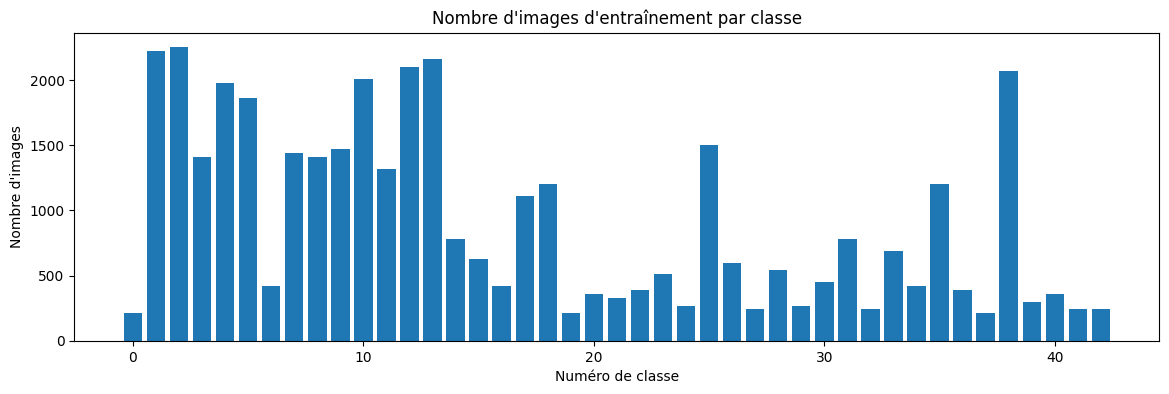

Classe la plus rare : 210 images | la plus fréquente : 2250 images | rapport : 10.7


In [ ]:
plt.figure(figsize=(14, 4))
plt.bar(compte.index, compte.values)
plt.title("Nombre d'images d'entraînement par classe")
plt.xlabel("Numéro de classe")
plt.ylabel("Nombre d'images")
plt.show()

# rapport entre la classe la plus fréquente et la plus rare, pour chiffrer le déséquilibre
print("Classe la plus rare :", compte.min(), "images | la plus fréquente :", compte.max(),
      "images | rapport :", round(compte.max() / compte.min(), 1))

**Déséquilibre :** il y a un facteur 10 entre la classe la plus rare (210 images) et la plus fréquente (2 250). Les limitations 30 et 50 km/h sont très représentées, alors que certains panneaux de danger ont à peine 200 images. Un modèle peut donc avoir une très bonne accuracy globale en étant mauvais sur les classes rares, qui pèsent peu dans la moyenne. C'est pour ça qu'en partie 5 on ne se contente pas de l'accuracy et qu'on regarde les résultats classe par classe.

In [ ]:
# taille des images d'origine, avant tout redimensionnement
train_df[["Width", "Height"]].describe().round(1)

,Width,Height
count,39209.0,39209.0
mean,50.8,50.3
std,24.3,23.1
min,25.0,25.0
25%,35.0,35.0
50%,43.0,43.0
75%,58.0,58.0
max,243.0,225.0


In [ ]:
exemple = Image.open(os.path.join(DOSSIER, train_df["Path"][0]))
print("Format :", exemple.format, "| Mode :", exemple.mode, "| Taille :", exemple.size)

Format : PNG | Mode : RGB | Taille : (27, 26)


Les images sont des PNG en couleur (RGB, 3 canaux) et leur taille varie beaucoup : de 25 px à plus de 200 px de côté, avec une médiane autour de 43 px. Elles sont à peu près carrées (largeur et hauteur moyennes quasi identiques), donc on peut les redimensionner en carré sans trop les déformer.

Une image au hasard pour chaque classe :

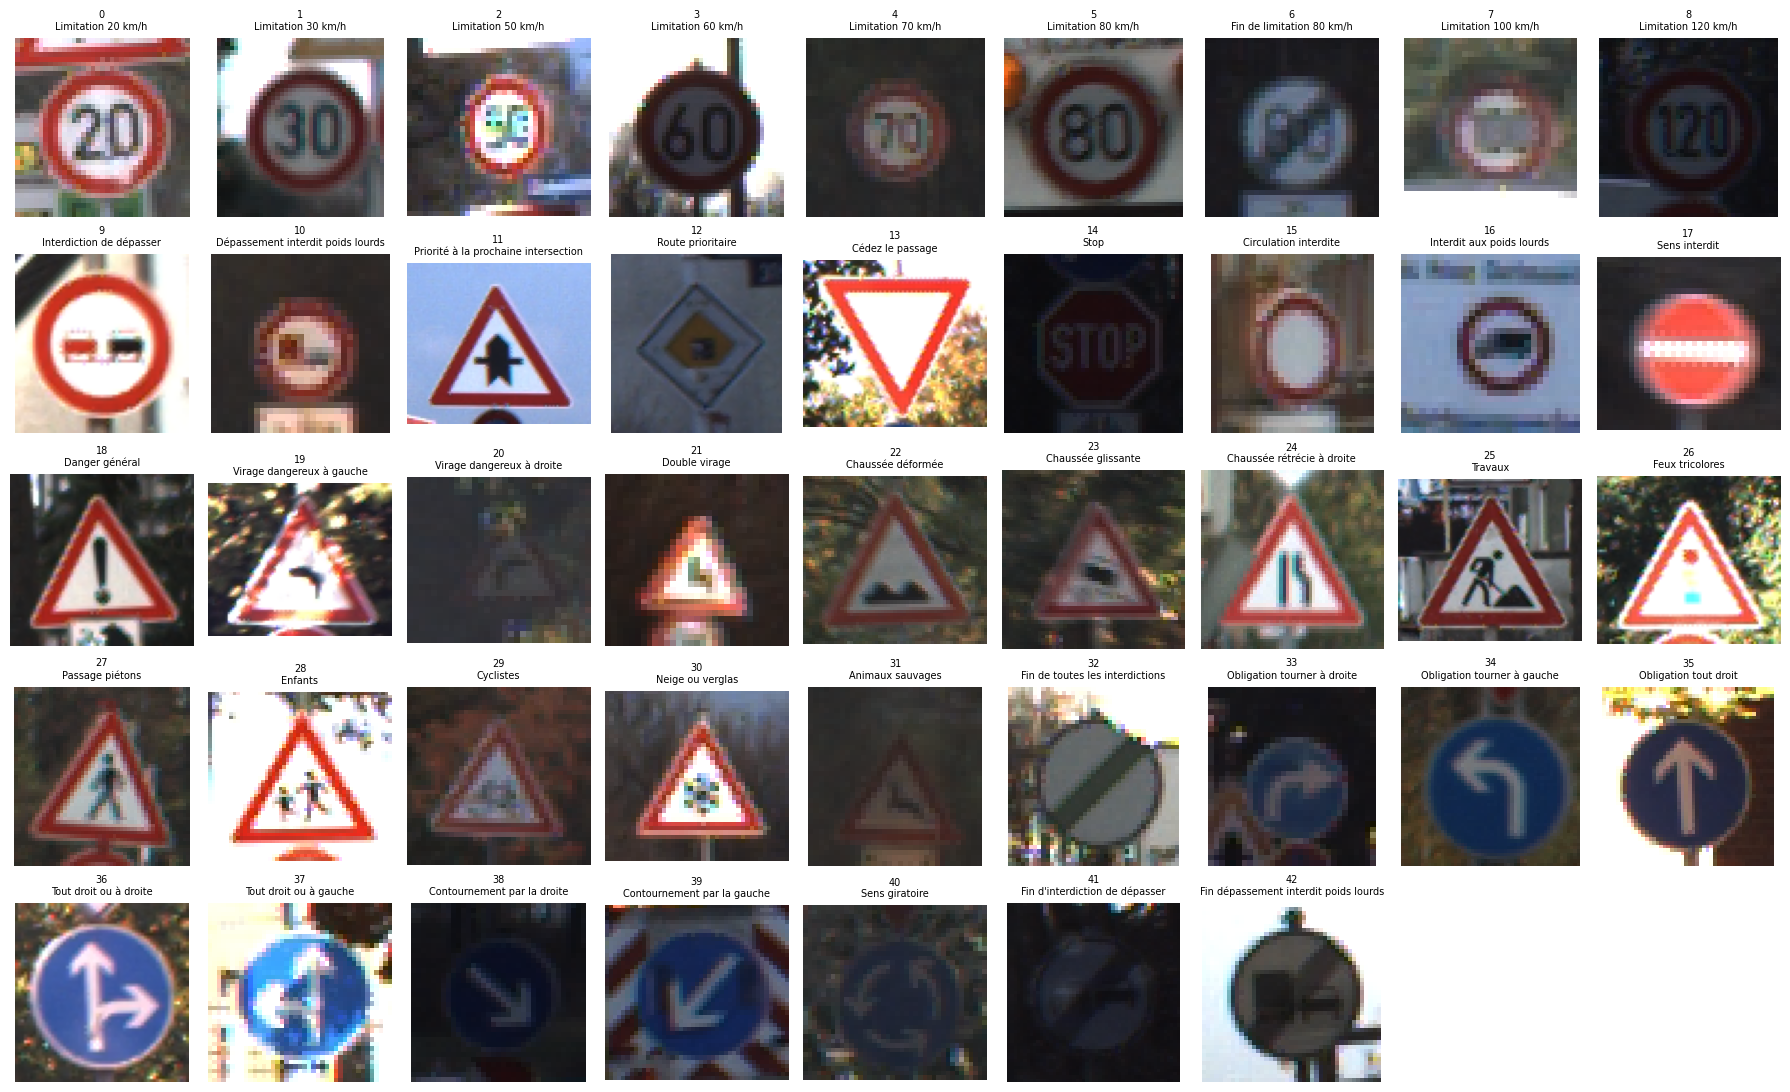

In [ ]:
fig, axes = plt.subplots(5, 9, figsize=(18, 11))  # 45 cases pour 43 classes, les 2 dernières restent vides
for i, ax in enumerate(axes.flat):
    ax.axis("off")
    if i < NB_CLASSES:
        chemin = train_df[train_df["ClassId"] == i].sample(1, random_state=0)["Path"].values[0]
        ax.imshow(Image.open(os.path.join(DOSSIER, chemin)))
        ax.set_title(f"{i}\n{NOMS_CLASSES[i]}", fontsize=7)
plt.tight_layout()
plt.show()

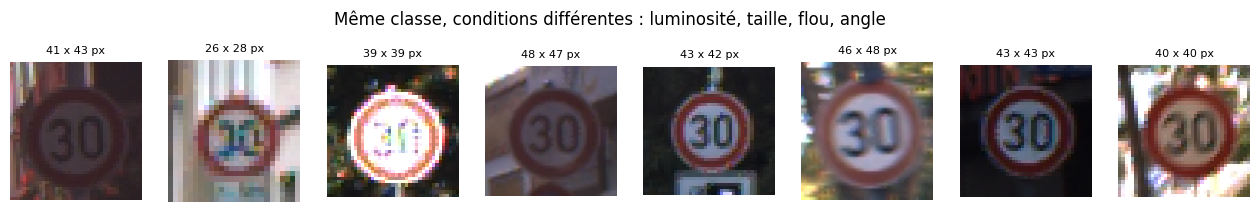

In [ ]:
# 8 images de la même classe (30 km/h) pour voir à quel point les conditions de prise de vue varient
echantillon = train_df[train_df["ClassId"] == 1].sample(8, random_state=1)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for ax, (_, ligne) in zip(axes, echantillon.iterrows()):
    ax.imshow(Image.open(os.path.join(DOSSIER, ligne["Path"])))
    ax.set_title(f"{ligne['Width']} x {ligne['Height']} px", fontsize=8)
    ax.axis("off")
fig.suptitle("Même classe, conditions différentes : luminosité, taille, flou, angle")
plt.show()

### 1.3 Préparation des données

Ce qu'on fait et pourquoi :

- **Redimensionnement en 32 x 32.** Un réseau attend des entrées de taille fixe. 32 x 32 est la taille classique pour GTSRB : assez pour reconnaître la forme et la couleur d'un panneau, et l'entraînement reste rapide. Le défaut, c'est que les petits pictogrammes deviennent flous (on le verra dans l'analyse des erreurs).
- **Normalisation (division par 255).** Les pixels passent de [0, 255] à [0, 1]. Avec des entrées petites et à la même échelle, la descente de gradient est plus stable.
- **Labels.** Chaque image garde son numéro de classe (0 à 42) tiré de la colonne `ClassId`.
- **Encodage.** On ne fait pas de one-hot : on garde les entiers et on utilise la perte `sparse_categorical_crossentropy`, qui donne exactement le même résultat que `categorical_crossentropy` sur des labels one-hot, sans avoir à stocker des vecteurs de 43 cases.
- **Train / validation / test.** Le train sert à apprendre les poids, la validation à comparer les modèles et régler les hyperparamètres, et le test sert **une seule fois** à la fin pour avoir une estimation honnête. Si on choisissait le modèle en regardant le test, son score ne serait plus vraiment une mesure sur des données inconnues.

In [ ]:
def charger_images(liste_chemins):
    """Ouvre chaque image, la passe en RGB et la redimensionne. Renvoie un tableau (N, 32, 32, 3) en uint8."""
    images = []
    for chemin in liste_chemins:
        # convert("RGB") par sécurité, au cas où une image aurait un canal alpha ou serait en niveaux de gris
        img = Image.open(os.path.join(DOSSIER, chemin)).convert("RGB")
        img = img.resize((TAILLE_IMAGE, TAILLE_IMAGE))
        images.append(np.array(img))
    return np.array(images)

In [ ]:
debut = time.time()
X_tout = charger_images(train_df["Path"])   # "tout" = train + validation, on les sépare juste après
y_tout = train_df["ClassId"].values
X_test = charger_images(test_df["Path"])
y_test = test_df["ClassId"].values
print(f"Chargement terminé en {time.time() - debut:.0f} s")

print("X_tout :", X_tout.shape, "| y_tout :", y_tout.shape)
print("X_test :", X_test.shape, "| y_test :", y_test.shape)

Chargement terminé en 18 s
X_tout : (39209, 32, 32, 3) | y_tout : (39209,)
X_test : (12630, 32, 32, 3) | y_test : (12630,)


In [ ]:
print("Avant normalisation :", X_tout.dtype, "min =", X_tout.min(), "max =", X_tout.max())

# float32 : c'est le type qu'utilise TensorFlow, et ça prend 2 fois moins de mémoire que float64
X_tout = X_tout.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0   # le test doit subir exactement le même prétraitement

print("Après normalisation :", X_tout.dtype, "min =", X_tout.min(), "max =", X_tout.max())

Avant normalisation : uint8 min = 0 max = 255
Après normalisation : float32 min = 0.0 max = 1.0


In [ ]:
# les labels sont des entiers, c'est ce qu'attend sparse_categorical_crossentropy
print("Exemples de labels :", y_tout[:10])

# juste pour comparer : à quoi ressemblerait le label 2 en one-hot
print("Label 2 en one-hot :", keras.utils.to_categorical(2, NB_CLASSES))

Exemples de labels : [20 20 20 20 20 20 20 20 20 20]
Label 2 en one-hot : [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


**Le piège du découpage train / validation.** Comme une série contient une trentaine de photos quasi identiques du même panneau, un `train_test_split` aléatoire mettrait des photos d'une même série des deux côtés. Le modèle serait alors validé sur des images qu'il a pratiquement déjà vues, et le score de validation serait trop optimiste.

On garde donc chaque série entière d'un seul côté. Le numéro de série est dans le nom du fichier : `00020_00004_00002.png` correspond à la classe 20, série 4, image 2. `StratifiedGroupKFold` de scikit-learn fait exactement ça : il découpe par groupes (les séries) tout en essayant de respecter la proportion de chaque classe.

Le test officiel (12 630 images) est déjà fourni à part, on n'y touche plus jusqu'à l'évaluation finale.

In [ ]:
noms_fichiers = train_df["Path"].apply(os.path.basename)          # ex. "00020_00004_00002.png"
series = noms_fichiers.str.rsplit("_", n=1).str[0]                # ex. "00020_00004" = classe + série
print("Nombre de séries :", series.nunique())                     # = nombre de panneaux physiques

Nombre de séries : 1307


In [ ]:
# 5 folds -> on prend le premier : 80 % train, 20 % validation
decoupe = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_val = next(decoupe.split(X_tout, y_tout, groups=series))

X_train, y_train = X_tout[idx_train], y_tout[idx_train]
X_val, y_val = X_tout[idx_val], y_tout[idx_val]
del X_tout  # plus besoin, on libère la RAM (Colab est vite limité)

print("Train :", X_train.shape, "| Validation :", X_val.shape, "| Test :", X_test.shape)

# deux vérifications
print("Séries communes train / validation :", len(set(series.iloc[idx_train]) & set(series.iloc[idx_val])))  # doit être 0
print("Classes présentes dans la validation :", len(np.unique(y_val)))

Train : (31349, 32, 32, 3) | Validation : (7860, 32, 32, 3) | Test : (12630, 32, 32, 3)
Séries communes train / validation : 0
Classes présentes dans la validation : 42


On obtient 31 349 images de train, 7 860 de validation et 12 630 de test, et aucune série n'est partagée entre train et validation, donc pas de fuite.

**Petit défaut :** la validation ne contient que 42 classes. La classe 24 « Chaussée rétrécie à droite » n'a que 9 séries, et comme le découpage déplace des séries entières, elles sont toutes tombées dans le train. Cette classe ne sera donc pas évaluée en validation (elle le sera sur le test, qui contient bien les 43 classes). On aurait pu parcourir les 5 folds et garder un découpage qui contient les 43 classes. Comme ça obligerait à relancer toutes les expériences, on l'a laissé tel quel et on le note dans les pistes d'amélioration.

## 2. Modèle de référence : un réseau dense

Avant de faire un CNN, on entraîne un réseau dense tout simple. Ça donne un point de comparaison pour voir ce que les convolutions apportent vraiment :

`Image -> Flatten -> Dense(256) + ReLU -> Dense(43) + Softmax`

In [ ]:
modele_dense = keras.Sequential([
    keras.Input(shape=(TAILLE_IMAGE, TAILLE_IMAGE, 3)),
    layers.Flatten(),                                  # 32*32*3 = 3072 valeurs, on perd la notion de voisinage
    layers.Dense(256, activation="relu"),
    layers.Dense(NB_CLASSES, activation="softmax"),    # une probabilité par classe
], name="reseau_dense")

modele_dense.summary()

Model: "reseau_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 797,739 (3.04 MB)

 Trainable params: 797,739 (3.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# mêmes réglages que pour le CNN ensuite (Adam, lr = 1e-3, batch 64) pour que la comparaison soit juste
modele_dense.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])

debut = time.time()
historique_dense = modele_dense.fit(X_train, y_train, validation_data=(X_val, y_val),
                                    epochs=EPOQUES_DENSE, batch_size=TAILLE_BATCH)
duree_dense = time.time() - debut
print(f"Durée : {duree_dense:.0f} s")

Epoch 1/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.5334 - loss: 1.9721 - val_accuracy: 0.6533 - val_loss: 1.4383
Epoch 2/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7924 - loss: 0.9107 - val_accuracy: 0.7455 - val_loss: 1.0312
Epoch 3/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8625 - loss: 0.6103 - val_accuracy: 0.7743 - val_loss: 0.9257
Epoch 4/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8897 - loss: 0.4747 - val_accuracy: 0.7929 - val_loss: 0.8550
Epoch 5/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9071 - loss: 0.3938 - val_accuracy: 0.8192 - val_loss: 0.7900
Epoch 6/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9192 - loss: 0.3424 - val_accuracy: 0.8388 - val_loss: 0.7437
Epoch 7/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9280 - loss: 0.3025 - val_accuracy: 0.8473 - val_loss: 0.7242
Epoch 8/15
490/490 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9354 - loss: 0.2734 - val_accuracy: 0

In [ ]:
def tracer_courbes(historique, titre):
    """Loss et accuracy (train et validation) au fil des époques, côte à côte."""
    h = historique.history
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(h["loss"], label="train")
    ax1.plot(h["val_loss"], label="validation")
    ax1.set_title(f"{titre} - loss")
    ax1.set_xlabel("Époque")
    ax1.legend()

    ax2.plot(h["accuracy"], label="train")
    ax2.plot(h["val_accuracy"], label="validation")
    ax2.set_title(f"{titre} - accuracy")
    ax2.set_xlabel("Époque")
    ax2.legend()

    plt.show()

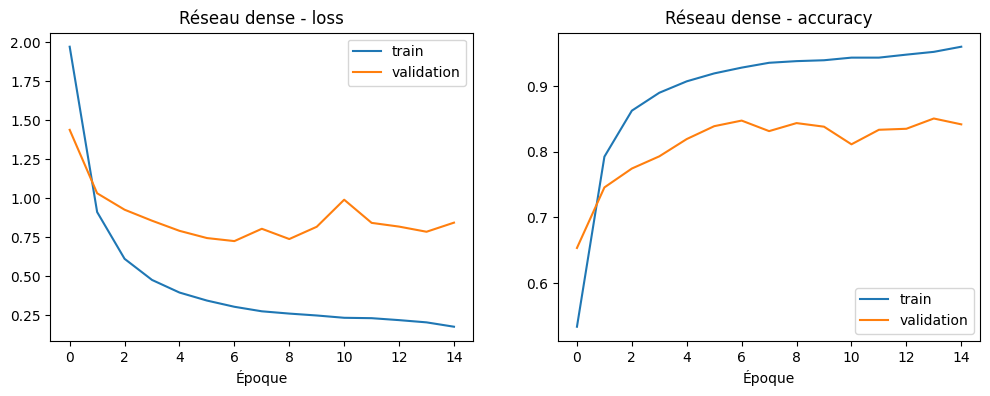

Réseau dense - accuracy validation : 0.8416


In [ ]:
tracer_courbes(historique_dense, "Réseau dense")

loss_dense, acc_dense = modele_dense.evaluate(X_val, y_val, verbose=0)
print(f"Réseau dense - accuracy validation : {acc_dense:.4f}")

### Ce qu'on retient du réseau dense

On arrive à 84,2 % en validation contre 95,4 % sur le train, soit 11 points d'écart.

Sur les courbes, la loss de validation atteint son minimum à l'époque 7 (0,72) puis remonte jusqu'à 0,84, alors que celle du train continue à baisser. C'est le signe classique du **surapprentissage** : le réseau apprend par cœur les images du train plutôt que des caractéristiques qui se généralisent.

Ce n'est pas étonnant vu l'architecture. Après le `Flatten`, l'image n'est plus qu'une liste de 3 072 nombres : le réseau ne sait pas quels pixels sont voisins, et un panneau décalé de quelques pixels active des entrées complètement différentes. En plus, la première couche Dense a déjà 786 688 paramètres (3 072 x 256 + 256), ce qui laisse beaucoup de place pour mémoriser.

On garde ce 84,2 % comme référence pour la suite.

## 3. Construction du CNN

### Architecture

`Image 32x32x3 -> [Conv 3x3 + ReLU] x 2 -> MaxPooling -> [Conv 3x3 + ReLU] x 2 -> MaxPooling -> Flatten -> Dense 256 + ReLU -> Dense 43 + Softmax`

Pourquoi ces choix :

- Un panneau se reconnaît d'abord à des éléments simples (bords, zones rouges, bleues ou blanches), puis à sa forme (cercle, triangle, octogone) et enfin à son pictogramme (chiffres, flèches, silhouettes). Deux blocs de convolution permettent de passer des motifs simples aux formes, ce qui semble suffisant pour des images aussi petites.
- On met deux convolutions 3 x 3 par bloc plutôt qu'une 5 x 5 : elles voient la même zone (champ récepteur 5 x 5), mais avec moins de paramètres (2 x 9 = 18 poids par canal contre 25) et une non-linéarité en plus. C'est l'idée de VGG.
- Le nombre de filtres double (32 puis 64) quand le pooling divise la taille par 2 : on compense la perte de résolution spatiale par plus de canaux, donc plus de types de motifs détectés.
- Avec des entrées en 32 x 32, deux poolings (32 -> 16 -> 8) suffisent. Un troisième donnerait des cartes de 4 x 4, ce qui nous a paru trop petit.
- `padding="same"` pour que les convolutions ne réduisent pas la taille : seul le pooling la divise, c'est plus simple à suivre.

### Dimensions et nombre de paramètres

Pour une convolution : (taille du kernel x taille du kernel x canaux d'entrée + 1 biais) x nombre de filtres.

| Couche | Sortie | Paramètres | Calcul |
|---|---|---|---|
| Entrée | 32 x 32 x 3 | 0 | |
| Conv2D 32, 3x3, same | 32 x 32 x 32 | 896 | (3 x 3 x 3 + 1) x 32 |
| Conv2D 32, 3x3, same | 32 x 32 x 32 | 9 248 | (3 x 3 x 32 + 1) x 32 |
| MaxPooling 2x2 | 16 x 16 x 32 | 0 | |
| Conv2D 64, 3x3, same | 16 x 16 x 64 | 18 496 | (3 x 3 x 32 + 1) x 64 |
| Conv2D 64, 3x3, same | 16 x 16 x 64 | 36 928 | (3 x 3 x 64 + 1) x 64 |
| MaxPooling 2x2 | 8 x 8 x 64 | 0 | |
| Flatten | 4 096 | 0 | 8 x 8 x 64 |
| Dense 256 | 256 | 1 048 832 | 4 096 x 256 + 256 |
| Dense 43 (Softmax) | 43 | 11 051 | 256 x 43 + 43 |
| **Total** | | **1 125 451** | |

Ce qui frappe : la couche Dense 256 représente à elle seule environ 93 % des paramètres, alors que les 4 convolutions n'en ont que 65 000 au total. C'est le partage des poids : un filtre 3 x 3 est appliqué sur toute l'image avec les mêmes poids. Si on voulait alléger le modèle, c'est clairement sur le `Flatten` + Dense qu'il faudrait jouer (par exemple avec un `GlobalAveragePooling2D`).

In [ ]:
def creer_cnn(nb_filtres=32, taux_dropout=0.0, augmentation=None):
    """CNN de la partie 3. Les arguments servent pour les expériences de la partie 6
    (plus de filtres, Dropout, Data Augmentation) sans avoir à recopier l'architecture."""
    modele = keras.Sequential(name="cnn")
    modele.add(keras.Input(shape=(TAILLE_IMAGE, TAILLE_IMAGE, 3)))

    # l'augmentation est mise en tête du modèle : elle n'est active que pendant fit()
    if augmentation is not None:
        modele.add(augmentation)

    # bloc 1 : 32x32 -> 16x16
    modele.add(layers.Conv2D(nb_filtres, (3, 3), padding="same", activation="relu"))
    modele.add(layers.Conv2D(nb_filtres, (3, 3), padding="same", activation="relu"))
    modele.add(layers.MaxPooling2D((2, 2)))

    # bloc 2 : deux fois plus de filtres, 16x16 -> 8x8
    modele.add(layers.Conv2D(nb_filtres * 2, (3, 3), padding="same", activation="relu"))
    modele.add(layers.Conv2D(nb_filtres * 2, (3, 3), padding="same", activation="relu"))
    modele.add(layers.MaxPooling2D((2, 2)))

    # partie classification
    modele.add(layers.Flatten())
    modele.add(layers.Dense(256, activation="relu"))
    if taux_dropout > 0:
        modele.add(layers.Dropout(taux_dropout))
    modele.add(layers.Dense(NB_CLASSES, activation="softmax"))
    return modele

In [ ]:
cnn_v1 = creer_cnn()   # version de base : 32 filtres, pas de Dropout, pas d'augmentation
cnn_v1.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,125,451 (4.29 MB)

 Trainable params: 1,125,451 (4.29 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# même info que summary() mais dans un DataFrame, plus facile à comparer avec notre tableau
lignes = []
for couche in cnn_v1.layers:
    lignes.append({
        "couche": couche.name,
        "dimensions de sortie": tuple(couche.output.shape[1:]),   # on enlève la dimension du batch
        "paramètres": couche.count_params(),
    })
pd.DataFrame(lignes)

,couche,dimensions de sortie,paramètres
0,conv2d,"(32, 32, 32)",896
1,conv2d_1,"(32, 32, 32)",9248
2,max_pooling2d,"(16, 16, 32)",0
3,conv2d_2,"(16, 16, 64)",18496
4,conv2d_3,"(16, 16, 64)",36928
5,max_pooling2d_1,"(8, 8, 64)",0
6,flatten_1,"(4096,)",0
7,dense_2,"(256,)",1048832
8,dense_3,"(43,)",11051


In [ ]:
# on revérifie deux lignes du tableau à la main
print("Conv2D n°1 :", (3 * 3 * 3 + 1) * 32, "paramètres")
print("Dense 256  :", 8 * 8 * 64 * 256 + 256, "paramètres")

Conv2D n°1 : 896 paramètres
Dense 256  : 1048832 paramètres


## 4. Entraînement

| Choix | Valeur | Pourquoi |
|---|---|---|
| Perte | `sparse_categorical_crossentropy` | Entropie croisée, la perte standard en classification multiclasse avec une sortie softmax. Version *sparse* parce que nos labels sont des entiers. |
| Optimiseur | Adam, lr = 0,001 | Adam adapte le pas pour chaque poids, il converge vite sans trop de réglages. 0,001 est sa valeur par défaut ; on teste une valeur plus grande en partie 6. |
| Batch size | 64 | Compromis entre un gradient pas trop bruité, un bon usage du GPU et la mémoire. |
| Époques | 30 max + Early Stopping | On arrête si la loss de validation ne s'améliore pas pendant 5 époques, et on récupère les poids de la meilleure époque. Ça évite de fixer le nombre d'époques un peu au hasard. |
| Métrique | Accuracy | Facile à lire, mais insuffisante seule à cause du déséquilibre : on la complète en partie 5. |

On surveille `val_loss` plutôt que `val_accuracy` pour l'Early Stopping : la loss est plus fine, elle bouge même quand l'accuracy stagne (par exemple si le modèle devient plus ou moins sûr de lui sur les mêmes prédictions).

In [ ]:
cnn_v1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])

arret_precoce = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

debut = time.time()
historique_v1 = cnn_v1.fit(X_train, y_train, validation_data=(X_val, y_val),
                           epochs=EPOQUES_MAX, batch_size=TAILLE_BATCH, callbacks=[arret_precoce])
duree_v1 = time.time() - debut
print(f"Durée : {duree_v1:.0f} s")

Epoch 1/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.7750 - loss: 0.8278 - val_accuracy: 0.9055 - val_loss: 0.3549
Epoch 2/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9855 - loss: 0.0575 - val_accuracy: 0.9307 - val_loss: 0.2902
Epoch 3/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9930 - loss: 0.0256 - val_accuracy: 0.9394 - val_loss: 0.3153
Epoch 4/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9952 - loss: 0.0162 - val_accuracy: 0.9420 - val_loss: 0.2591
Epoch 5/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9947 - loss: 0.0191 - val_accuracy: 0.9611 - val_loss: 0.1829
Epoch 6/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9953 - loss: 0.0152 - val_accuracy: 0.9467 - val_loss: 0.3077
Epoch 7/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9955 - loss: 0.0185 - val_accuracy: 0.9517 - val_loss: 0.2756
Epoch 8/30
490/490 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9979 - loss: 0.0078 - val_accuracy: 

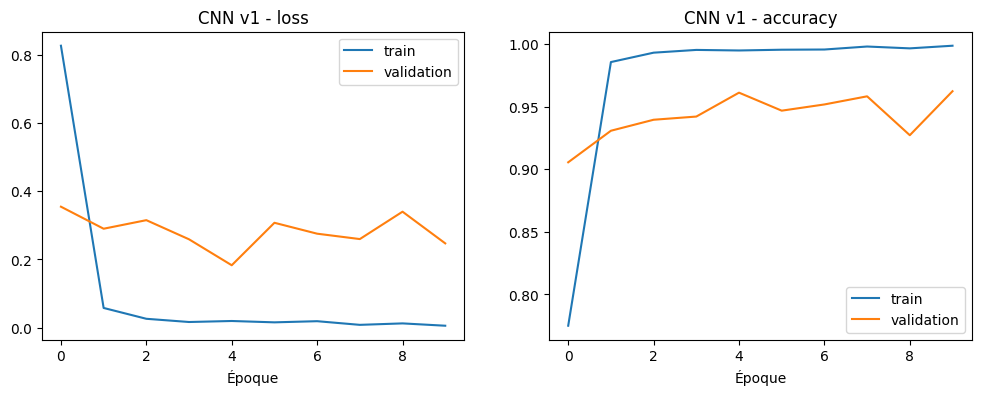

Réseau dense : 0.8416 | CNN v1 : 0.9611 (accuracy validation)


In [ ]:
tracer_courbes(historique_v1, "CNN v1")

loss_v1, acc_v1 = cnn_v1.evaluate(X_val, y_val, verbose=0)   # avec les poids restaurés par l'early stopping
print(f"Réseau dense : {acc_dense:.4f} | CNN v1 : {acc_v1:.4f} (accuracy validation)")

### Analyse des courbes du CNN v1

Le CNN arrive à **96,1 %** en validation, contre 84,2 % pour le réseau dense : 12 points de mieux. C'est l'intérêt des convolutions : le même filtre cherche le même motif partout dans l'image, donc un panneau un peu décalé reste reconnu, et le réseau garde l'information de voisinage entre pixels.

Par contre, il surapprend très vite. Dès l'époque 4 l'accuracy de train dépasse 99,5 % et la loss de train est quasi nulle, alors que la loss de validation oscille entre 0,18 et 0,34 sans vraiment descendre. Le modèle a déjà appris le train par cœur au bout de quelques époques.

L'Early Stopping a bien fait son travail : la meilleure loss de validation (0,18) est obtenue à l'époque 5, l'entraînement s'arrête à l'époque 10 après 5 époques sans amélioration, et ce sont les poids de l'époque 5 qui sont gardés.

Le CNN est donc nettement meilleur que le réseau dense, mais il surapprend. D'où l'idée de tester de la régularisation (Dropout, Data Augmentation) en partie 6.

### Feature maps de la première couche

Pour voir concrètement ce que fait une convolution, on affiche la sortie de quelques filtres de la première couche du CNN entraîné, sur une image de validation.

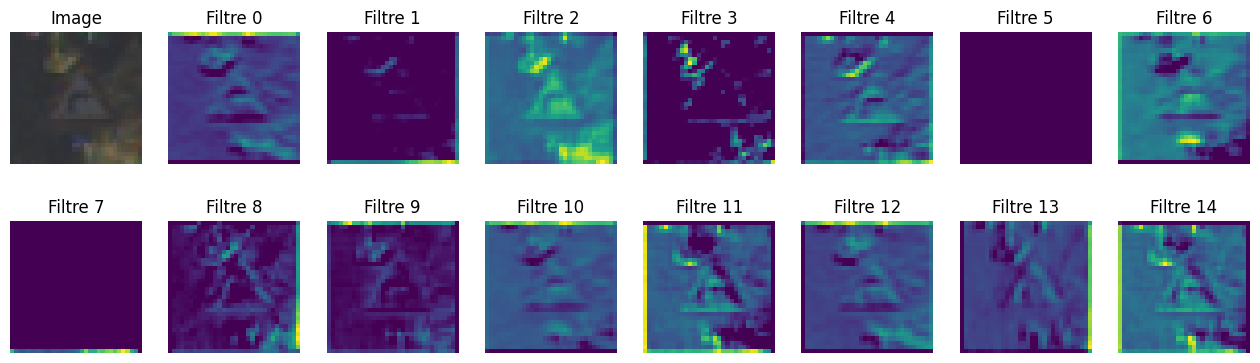

In [ ]:
# petit modèle qui s'arrête à la sortie de la 1re convolution
extracteur = keras.Model(inputs=cnn_v1.inputs, outputs=cnn_v1.layers[0].output)
cartes = extracteur.predict(X_val[:1], verbose=0)   # forme (1, 32, 32, 32) : 32 cartes de 32x32

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
axes[0, 0].imshow(X_val[0])
axes[0, 0].set_title("Image")
for k, ax in enumerate(axes.flat[1:]):   # on n'affiche que les 15 premiers filtres sur 32
    ax.imshow(cartes[0, :, :, k], cmap="viridis")
    ax.set_title(f"Filtre {k}")
for ax in axes.flat:
    ax.axis("off")
plt.show()

Sur ces cartes, certains filtres réagissent aux bords du panneau, d'autres aux zones rouges ou aux zones claires du fond. Ce sont des détecteurs assez basiques, ce qui correspond bien à ce qu'on attend d'une première couche.

## 5. Évaluation et analyse des erreurs

Avec des classes aussi déséquilibrées, l'accuracy globale ne dit pas tout. On regarde donc aussi la matrice de confusion, les scores par classe et des exemples d'erreurs.

Attention : on fait cette analyse sur la **validation**. Le test est gardé pour l'évaluation du modèle final, à la fin de la partie 6.

In [ ]:
probas_val = cnn_v1.predict(X_val, verbose=0)   # (nb images, 43)
pred_val = probas_val.argmax(axis=1)
print("Accuracy validation :", round((pred_val == y_val).mean(), 4))   # on doit retrouver le score de evaluate()

Accuracy validation : 0.9611


In [ ]:
def afficher_matrice_confusion(y_vrai, y_pred, titre):
    """Affiche la matrice de confusion normalisée par ligne et renvoie la matrice brute (en nombre d'images)."""
    matrice = confusion_matrix(y_vrai, y_pred, labels=range(NB_CLASSES))   # ligne = vraie classe, colonne = prédite

    # normalisation par ligne : chaque case = proportion de la vraie classe.
    # le where évite une division par 0 pour une classe absente (la classe 24 en validation)
    totaux = matrice.sum(axis=1, keepdims=True)
    matrice_pct = np.divide(matrice, totaux, out=np.zeros(matrice.shape), where=totaux > 0)

    plt.figure(figsize=(10, 9))
    plt.imshow(matrice_pct, cmap="Blues")
    plt.colorbar()
    plt.title(titre)
    plt.xlabel("Classe prédite")
    plt.ylabel("Vraie classe")
    plt.xticks(range(NB_CLASSES), fontsize=6)
    plt.yticks(range(NB_CLASSES), fontsize=6)
    plt.show()
    return matrice

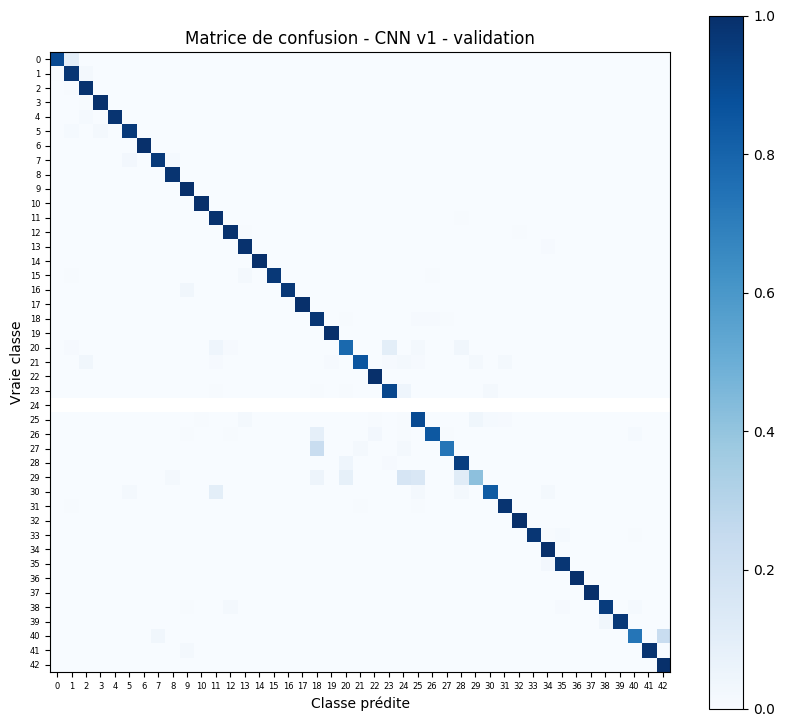

In [ ]:
matrice_val = afficher_matrice_confusion(y_val, pred_val, "Matrice de confusion - CNN v1 - validation")

In [ ]:
# zero_division=0 : la classe 24 n'a aucune image en validation, sinon sklearn affiche un warning
print(classification_report(y_val, pred_val, labels=range(NB_CLASSES), target_names=NOMS_CLASSES,
                            digits=3, zero_division=0))

                                       precision    recall  f1-score   support

                   Limitation 20 km/h      0.931     0.900     0.915        30
                   Limitation 30 km/h      0.962     0.974     0.968       420
                   Limitation 50 km/h      0.963     0.988     0.975       480
                   Limitation 60 km/h      0.978     0.993     0.985       270
                   Limitation 70 km/h      0.998     0.981     0.989       420
                   Limitation 80 km/h      0.969     0.961     0.965       330
            Fin de limitation 80 km/h      0.989     1.000     0.994        90
                  Limitation 100 km/h      0.984     0.961     0.972       330
                  Limitation 120 km/h      0.977     0.983     0.980       300
             Interdiction de dépasser      0.968     1.000     0.984       240
    Dépassement interdit poids lourds      0.995     1.000     0.998       420
 Priorité à la prochaine intersection      0.958   

In [ ]:
def tableau_confusions(matrice, nb=10):
    """Les nb confusions (vraie classe -> classe prédite) les plus fréquentes, hors diagonale."""
    confusions = []
    for vraie in range(NB_CLASSES):
        for predite in range(NB_CLASSES):
            if vraie != predite and matrice[vraie, predite] > 0:
                confusions.append({
                    "vraie classe": NOMS_CLASSES[vraie],
                    "classe prédite": NOMS_CLASSES[predite],
                    "nb erreurs": matrice[vraie, predite],
                })
    return pd.DataFrame(confusions).sort_values("nb erreurs", ascending=False).head(nb)

In [ ]:
tableau_confusions(matrice_val)

,vraie classe,classe prédite,nb erreurs
103,Sens giratoire,Fin dépassement interdit poids lourds,14
74,Passage piétons,Danger général,14
69,Feux tricolores,Danger général,13
64,Travaux,Cyclistes,11
82,Cyclistes,Chaussée rétrécie à droite,10
83,Cyclistes,Travaux,9
42,Virage dangereux à droite,Chaussée glissante,9
96,Obligation tout droit,Obligation tourner à gauche,8
19,Limitation 100 km/h,Limitation 80 km/h,8
98,Contournement par la droite,Route prioritaire,8


In [ ]:
# accuracy par classe = diagonale / total de la ligne (c'est le recall de chaque classe)
totaux = matrice_val.sum(axis=1)
acc_par_classe = np.divide(matrice_val.diagonal(), totaux, out=np.full(NB_CLASSES, np.nan), where=totaux > 0)

perf_classes = pd.DataFrame({
    "classe": NOMS_CLASSES,
    "accuracy": acc_par_classe.round(3),
    "images d'entraînement": np.bincount(y_train, minlength=NB_CLASSES),
})
perf_classes.sort_values("accuracy").head(8)   # la classe 24 (NaN) est rangée à la fin

,classe,accuracy,images d'entraînement
29,Cyclistes,0.417,210
27,Passage piétons,0.733,180
40,Sens giratoire,0.733,300
20,Virage dangereux à droite,0.778,270
30,Neige ou verglas,0.833,390
26,Feux tricolores,0.847,450
21,Double virage,0.856,240
25,Travaux,0.897,1200


In [ ]:
def afficher_exemples(X, y_vrai, probas, indices, titre):
    """10 images avec vraie classe, classe prédite et confiance. Titre vert si juste, rouge si faux."""
    fig, axes = plt.subplots(2, 5, figsize=(16, 8), constrained_layout=True)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, indices):
        pred = probas[i].argmax()
        couleur = "green" if pred == y_vrai[i] else "red"
        ax.imshow(X[i])
        ax.set_title(f"Vraie : {NOMS_CLASSES[y_vrai[i]]}\nPrédite : {NOMS_CLASSES[pred]}\nProba : {probas[i].max():.2f}",
                     fontsize=8, color=couleur)
    fig.suptitle(titre)
    plt.show()

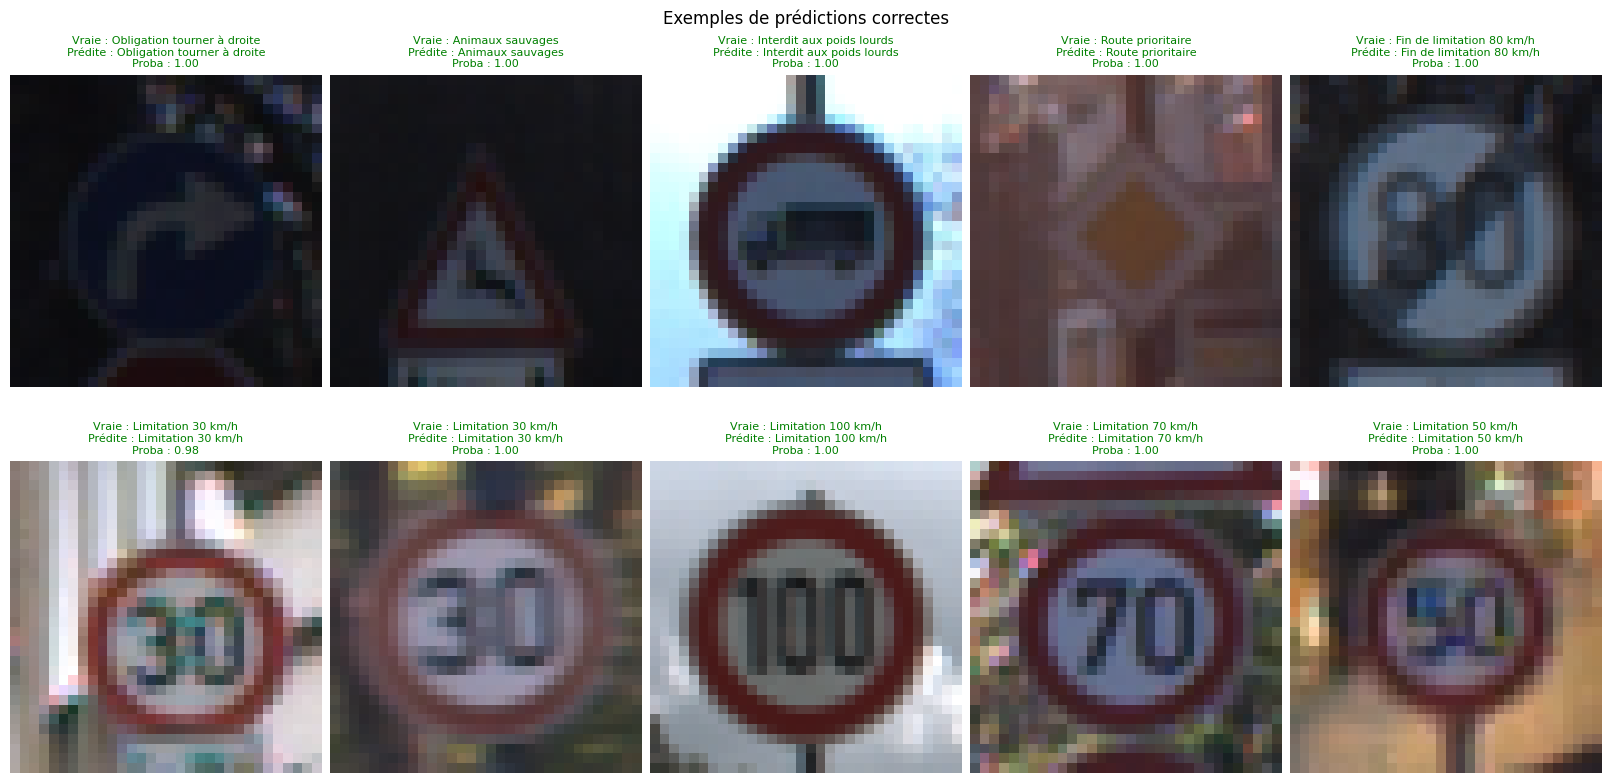

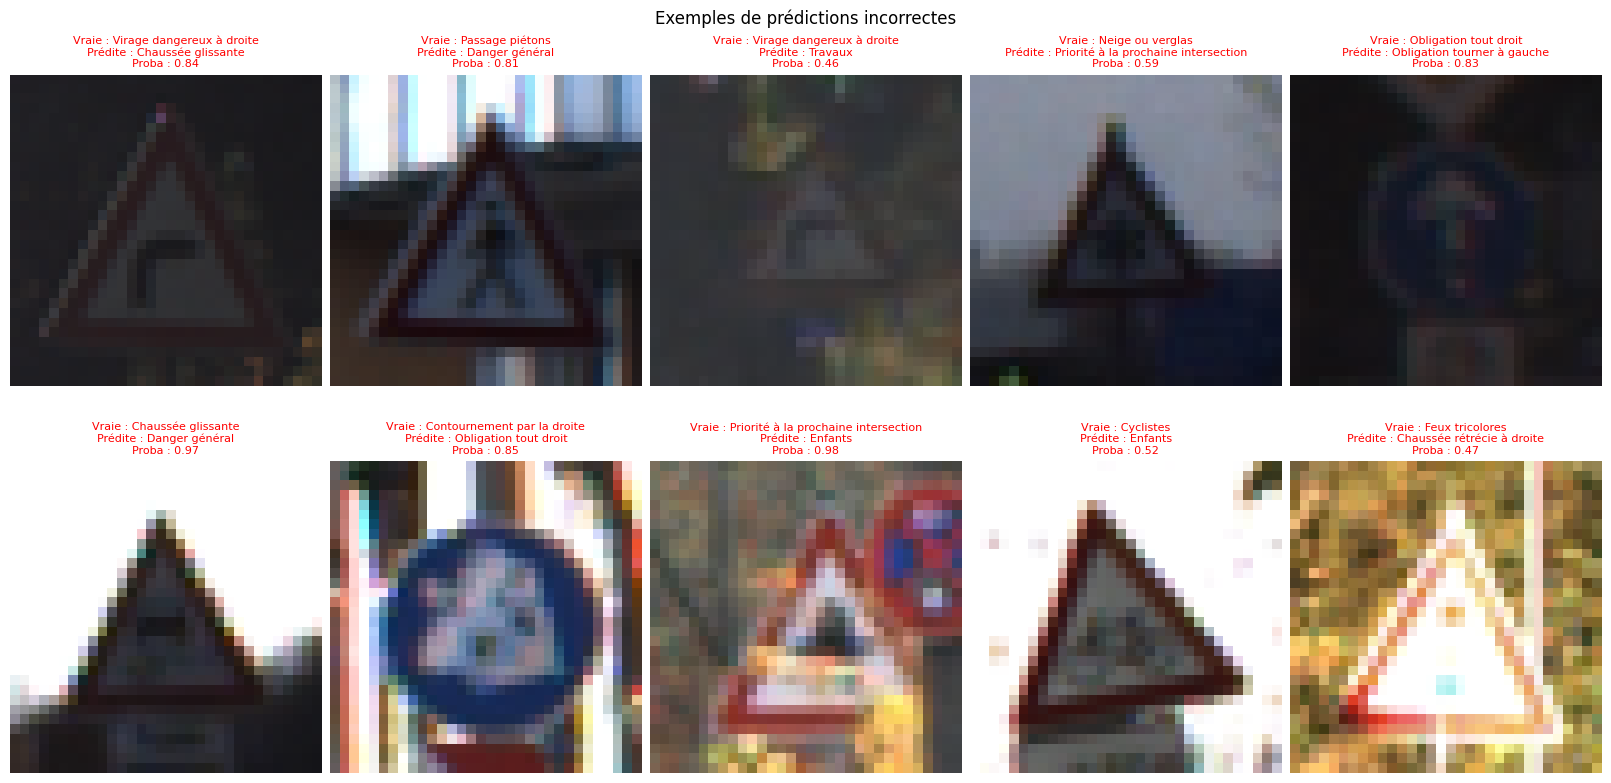

In [ ]:
rng = np.random.default_rng(0)   # graine fixe pour retomber sur les mêmes exemples
bonnes = np.where(pred_val == y_val)[0]
erreurs = np.where(pred_val != y_val)[0]

afficher_exemples(X_val, y_val, probas_val, rng.choice(bonnes, size=min(10, len(bonnes)), replace=False),
                  "Exemples de prédictions correctes")
afficher_exemples(X_val, y_val, probas_val, rng.choice(erreurs, size=min(10, len(erreurs)), replace=False),
                  "Exemples de prédictions incorrectes")

### Est-ce que la luminosité ou la taille jouent ?

Sur les exemples d'erreurs ci-dessus, plusieurs images sont très sombres, très claires ou toutes petites. Pour voir si c'est une tendance générale, on compare deux grandeurs mesurables entre images bien et mal classées : la luminosité moyenne de l'image et la largeur d'origine du panneau (avant le passage en 32 x 32).

In [ ]:
luminosite = X_val.mean(axis=(1, 2, 3))           # moyenne de tous les pixels, entre 0 et 1
largeur = train_df["Width"].values[idx_val]        # idx_val indexe bien train_df (même ordre que X_tout)
juste = pred_val == y_val

print(f"Luminosité moyenne : bien classées = {luminosite[juste].mean():.3f} | mal classées = {luminosite[~juste].mean():.3f}")
print(f"Largeur d'origine moyenne : bien classées = {largeur[juste].mean():.1f} px | mal classées = {largeur[~juste].mean():.1f} px")

Luminosité moyenne : bien classées = 0.315 | mal classées = 0.412
Largeur d'origine moyenne : bien classées = 49.7 px | mal classées = 51.6 px


### Analyse des erreurs (CNN v1, validation)

**Ce qui marche bien.** La grande majorité des classes dépasse 95 %. Plusieurs sont reconnues à 100 % (recall), comme « Stop », « Sens interdit », « Tout droit ou à droite », « Tout droit ou à gauche » ou « Fin de limitation 80 km/h ». Ce sont des panneaux très reconnaissables par leur forme ou leur couleur. Le nombre d'images n'explique pas tout : « Tout droit ou à gauche » n'a que 210 images de train et ne fait pourtant aucune erreur.

**Les classes les plus difficiles :**

| Classe | Accuracy | Images de train |
|---|---|---|
| Cyclistes | 41,7 % | 210 |
| Passage piétons | 73,3 % | 180 |
| Sens giratoire | 73,3 % | 300 |
| Virage dangereux à droite | 77,8 % | 270 |
| Neige ou verglas | 83,3 % | 390 |

À notre avis, deux choses se cumulent :
1. **Peu d'exemples.** Ce sont des classes rares (180 à 390 images, contre plus de 2 000 pour les limitations 30 et 50). Le modèle a moins d'occasions d'apprendre leurs détails.
2. **Des classes qui se ressemblent.** Sauf le sens giratoire, ce sont tous des triangles rouges de danger : même forme, mêmes couleurs, seul le petit pictogramme noir au centre change. En 32 x 32, ce pictogramme ne fait plus que quelques pixels.

**Les confusions les plus fréquentes** vont dans le même sens : « Passage piétons » prédit « Danger général » (14 erreurs), « Feux tricolores » prédit « Danger général » (13), « Travaux » et « Cyclistes » confondus dans les deux sens. On a aussi des confusions entre limitations de vitesse (100 km/h prise pour 80 km/h, 8 erreurs), où seul un chiffre change. La confusion la plus fréquente, « Sens giratoire » prédit « Fin dépassement interdit poids lourds » (14), est plus surprenante puisque l'un est bleu et l'autre blanc et gris. On pense que ça vient d'images sombres où le bleu ne se distingue plus bien, mais on n'a pas vérifié plus en détail.

On note aussi que « Cyclistes » est prédit 10 fois comme « Chaussée rétrécie à droite », la classe absente de la validation : le modèle la connaît quand même puisqu'elle est dans le train.

**Luminosité et taille :**
- Les images mal classées sont en moyenne **plus claires** que les bien classées (0,41 contre 0,32). On s'attendait plutôt au contraire. Une explication possible : la surexposition (soleil, contre-jour) qui « efface » le pictogramme. Mais ça reste une corrélation, pas une preuve : certaines classes sont naturellement plus claires que d'autres, et les classes difficiles ne sont pas réparties au hasard.
- La taille d'origine ne semble pas jouer (51,6 px en moyenne pour les erreurs, 49,7 px pour les bonnes réponses).
- Visuellement, sur les exemples d'erreurs, on voit aussi des images floues, très petites ou prises de biais.

## 6. Expériences pour améliorer le modèle

**Méthode :** chaque expérience ne change **qu'une seule chose** par rapport à une version précédente, sinon on ne pourrait pas savoir à quoi attribuer l'effet observé. Toutes les expériences sont comparées sur la validation, avec le même Early Stopping.

| Expérience | Modification | Question |
|---|---|---|
| 1 | CNN v1 + Dropout 0,5 | Le Dropout réduit-il le surapprentissage ? |
| 2 | Exp. 1 + Data Augmentation | Est-ce que voir des images légèrement transformées aide à généraliser ? |
| 3 | Exp. 2 avec deux fois plus de filtres (64 / 128) | Un modèle plus large apprend-il mieux ? |
| 4 | Exp. 2 avec un learning rate de 0,01 | Que se passe-t-il avec un pas de gradient trop grand ? |

Pour ne pas réécrire 4 fois la même chose, on fait deux petites fonctions : une qui entraîne un modèle avec le protocole commun, et une qui enregistre ses scores dans un tableau.

In [ ]:
resultats = []   # une ligne par modèle, pour le tableau comparatif
modeles = {}     # on garde les modèles entraînés pour choisir le meilleur ensuite


def enregistrer(nom, modification, modele, historique, duree):
    """Calcule les scores d'un modèle déjà entraîné et ajoute une ligne à `resultats`."""
    loss_val, acc_val = modele.evaluate(X_val, y_val, verbose=0)
    # accuracy train recalculée avec evaluate() : sans Dropout ni augmentation, donc comparable à la validation
    acc_train = modele.evaluate(X_train, y_train, verbose=0)[1]
    resultats.append({
        "expérience": nom,
        "modification": modification,
        "accuracy train": acc_train,
        "accuracy validation": acc_val,
        "écart train - val": acc_train - acc_val,   # grand écart = surapprentissage
        "loss validation": loss_val,
        "époques": len(historique.history["loss"]),
        "paramètres": modele.count_params(),
        "durée (s)": round(duree),
    })
    modeles[nom] = modele


def lancer_experience(nom, modification, modele, learning_rate=0.001, epoques=EPOQUES_MAX):
    """Compile, entraîne avec early stopping, enregistre et trace les courbes. Même protocole pour tout le monde."""
    modele.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    debut = time.time()
    historique = modele.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epoques,
                            batch_size=TAILLE_BATCH, callbacks=[arret], verbose=2)  # verbose=2 : une ligne par époque
    enregistrer(nom, modification, modele, historique, time.time() - debut)

    tracer_courbes(historique, nom)
    print(f"{nom} : accuracy validation = {resultats[-1]['accuracy validation']:.4f}")

In [ ]:
# on ajoute d'abord les deux modèles déjà entraînés pour avoir tout dans le même tableau
enregistrer("Réseau dense", "Modèle de référence (partie 2)", modele_dense, historique_dense, duree_dense)
enregistrer("CNN v1", "CNN de base (partie 3)", cnn_v1, historique_v1, duree_v1)
pd.DataFrame(resultats).round(4)

,expérience,modification,accuracy train,accuracy validation,écart train - val,loss validation,époques,paramètres,durée (s)
0,Réseau dense,Modèle de référence (partie 2),0.9544,0.8416,0.1128,0.8426,15,797739,33
1,CNN v1,CNN de base (partie 3),0.9993,0.9611,0.0382,0.1829,10,1125451,58


### Expérience 1 : Dropout

À chaque pas d'entraînement, le Dropout met à zéro 50 % des neurones de la couche Dense 256, tirés au hasard. Le réseau ne peut plus s'appuyer sur quelques neurones très spécialisés, il est obligé de répartir l'information, ce qui limite la mémorisation. En prédiction, Keras le désactive automatiquement.

On le met uniquement après la Dense 256 parce que c'est là que sont 93 % des paramètres, donc là que le modèle a le plus de capacité à mémoriser.

Epoch 1/30
490/490 - 11s - 23ms/step - accuracy: 0.6326 - loss: 1.3099 - val_accuracy: 0.9221 - val_loss: 0.2756
Epoch 2/30
490/490 - 4s - 8ms/step - accuracy: 0.9470 - loss: 0.1788 - val_accuracy: 0.9588 - val_loss: 0.1492
Epoch 3/30
490/490 - 4s - 8ms/step - accuracy: 0.9740 - loss: 0.0881 - val_accuracy: 0.9565 - val_loss: 0.1947
Epoch 4/30
490/490 - 4s - 8ms/step - accuracy: 0.9798 - loss: 0.0666 - val_accuracy: 0.9644 - val_loss: 0.1312
Epoch 5/30
490/490 - 4s - 8ms/step - accuracy: 0.9863 - loss: 0.0441 - val_accuracy: 0.9696 - val_loss: 0.1126
Epoch 6/30
490/490 - 4s - 9ms/step - accuracy: 0.9885 - loss: 0.0369 - val_accuracy: 0.9740 - val_loss: 0.1117
Epoch 7/30
490/490 - 4s - 8ms/step - accuracy: 0.9902 - loss: 0.0329 - val_accuracy: 0.9700 - val_loss: 0.1270
Epoch 8/30
490/490 - 4s - 8ms/step - accuracy: 0.9913 - loss: 0.0294 - val_accuracy: 0.9748 - val_loss: 0.1231
Epoch 9/30
490/490 - 4s - 9ms/step - accuracy: 0.9915 - loss: 0.0285 - val_accuracy: 0.9724 - val_loss: 0.1319

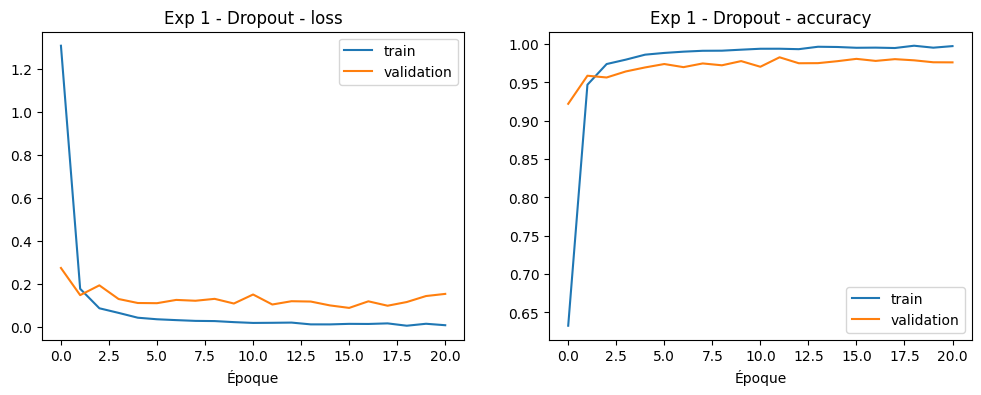

Exp 1 - Dropout : accuracy validation = 0.9808


In [ ]:
lancer_experience("Exp 1 - Dropout", "CNN v1 + Dropout 0,5", creer_cnn(taux_dropout=0.5))

### Expérience 2 : Data Augmentation

L'idée est de générer à chaque époque des versions légèrement modifiées des images de train. C'est un peu comme avoir plus de données, et surtout plus variées.

On a choisi des transformations qui **ne changent pas le sens du panneau** :
- une petite rotation (environ ±10°) : panneau un peu penché ou photo prise de biais ;
- un zoom et un décalage de 10 % : panneau plus ou moins gros, ou mal centré dans l'image ;
- une variation de luminosité : soleil, ombre, contre-jour.

On n'a **pas** mis de retournement horizontal. Ça aurait été une erreur ici : un « virage à gauche » retourné devient un « virage à droite », « obligation de tourner à gauche » devient « à droite », etc. L'image changerait de classe sans que son label change.

Les couches d'augmentation de Keras ne sont actives que pendant l'entraînement : les images de validation et de test ne sont pas modifiées.

In [ ]:
def creer_augmentation():
    """Nouveau bloc d'augmentation (on en recrée un par modèle pour ne pas partager les mêmes couches)."""
    return keras.Sequential([
        layers.RandomRotation(0.03),            # fraction d'un tour : 0.03 x 360° ≈ 10°
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomBrightness(0.2, value_range=(0.0, 1.0)),   # value_range à préciser car nos pixels sont dans [0, 1]
    ], name="augmentation")

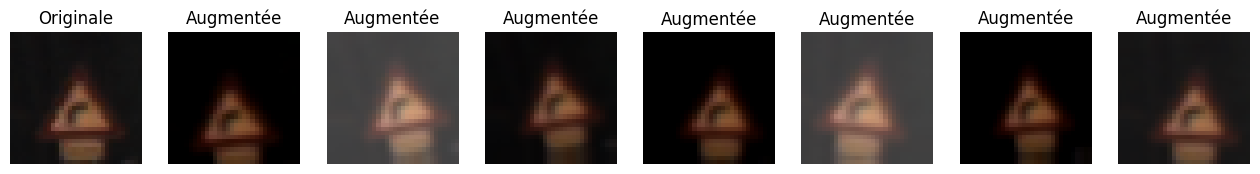

In [ ]:
# on vérifie visuellement que les transformations restent raisonnables
apercu = creer_augmentation()

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
axes[0].imshow(X_train[0])
axes[0].set_title("Originale")
for ax in axes[1:]:
    image_aug = apercu(X_train[:1], training=True)[0]   # training=True sinon l'augmentation ne fait rien
    ax.imshow(np.clip(np.array(image_aug), 0, 1))       # la luminosité peut sortir de [0, 1]
    ax.set_title("Augmentée")
for ax in axes:
    ax.axis("off")
plt.show()

Epoch 1/30
490/490 - 13s - 26ms/step - accuracy: 0.3067 - loss: 2.4181 - val_accuracy: 0.5901 - val_loss: 1.2535
Epoch 2/30
490/490 - 6s - 12ms/step - accuracy: 0.6442 - loss: 1.1142 - val_accuracy: 0.8656 - val_loss: 0.4384
Epoch 3/30
490/490 - 5s - 11ms/step - accuracy: 0.8087 - loss: 0.6078 - val_accuracy: 0.9275 - val_loss: 0.2431
Epoch 4/30
490/490 - 6s - 12ms/step - accuracy: 0.8694 - loss: 0.4106 - val_accuracy: 0.9482 - val_loss: 0.1603
Epoch 5/30
490/490 - 6s - 12ms/step - accuracy: 0.9021 - loss: 0.3182 - val_accuracy: 0.9669 - val_loss: 0.1038
Epoch 6/30
490/490 - 6s - 13ms/step - accuracy: 0.9230 - loss: 0.2570 - val_accuracy: 0.9746 - val_loss: 0.0933
Epoch 7/30
490/490 - 9s - 19ms/step - accuracy: 0.9357 - loss: 0.2121 - val_accuracy: 0.9752 - val_loss: 0.0855
Epoch 8/30
490/490 - 6s - 12ms/step - accuracy: 0.9434 - loss: 0.1908 - val_accuracy: 0.9758 - val_loss: 0.0897
Epoch 9/30
490/490 - 5s - 11ms/step - accuracy: 0.9506 - loss: 0.1634 - val_accuracy: 0.9838 - val_loss

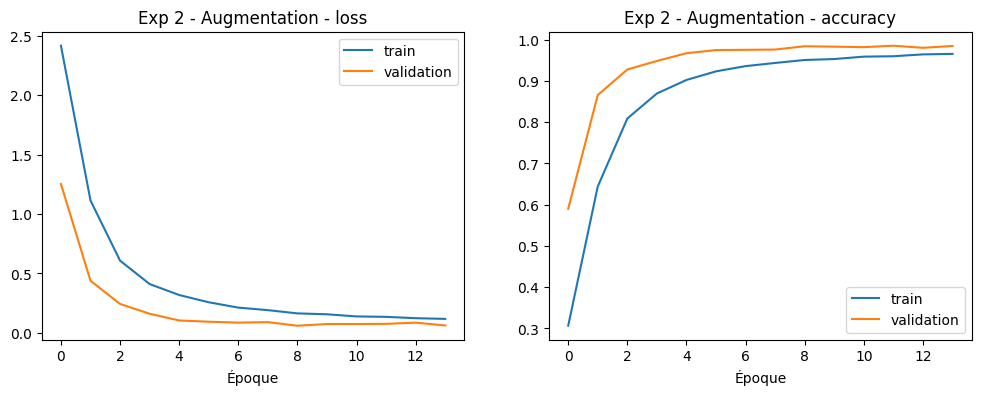

Exp 2 - Augmentation : accuracy validation = 0.9838


In [ ]:
lancer_experience("Exp 2 - Augmentation", "Exp 1 + Data Augmentation",
                  creer_cnn(taux_dropout=0.5, augmentation=creer_augmentation()))

### Expérience 3 : plus de filtres

On double le nombre de filtres de chaque convolution (64 puis 128 au lieu de 32 puis 64). Le réseau peut détecter plus de motifs différents, mais il a plus de paramètres, il est plus lent, et en théorie il risque de surapprendre davantage. On garde le Dropout et l'augmentation de l'expérience 2.

Epoch 1/30
490/490 - 12s - 24ms/step - accuracy: 0.3749 - loss: 2.1744 - val_accuracy: 0.7536 - val_loss: 0.8269
Epoch 2/30
490/490 - 8s - 17ms/step - accuracy: 0.7489 - loss: 0.8004 - val_accuracy: 0.9385 - val_loss: 0.2210
Epoch 3/30
490/490 - 8s - 16ms/step - accuracy: 0.8809 - loss: 0.3942 - val_accuracy: 0.9716 - val_loss: 0.1004
Epoch 4/30
490/490 - 8s - 16ms/step - accuracy: 0.9232 - loss: 0.2588 - val_accuracy: 0.9737 - val_loss: 0.1023
Epoch 5/30
490/490 - 8s - 17ms/step - accuracy: 0.9383 - loss: 0.2105 - val_accuracy: 0.9711 - val_loss: 0.1078
Epoch 6/30
490/490 - 8s - 16ms/step - accuracy: 0.9493 - loss: 0.1715 - val_accuracy: 0.9803 - val_loss: 0.0774
Epoch 7/30
490/490 - 8s - 16ms/step - accuracy: 0.9537 - loss: 0.1593 - val_accuracy: 0.9718 - val_loss: 0.1551
Epoch 8/30
490/490 - 8s - 16ms/step - accuracy: 0.9594 - loss: 0.1422 - val_accuracy: 0.9756 - val_loss: 0.1061
Epoch 9/30
490/490 - 8s - 16ms/step - accuracy: 0.9642 - loss: 0.1223 - val_accuracy: 0.9824 - val_loss

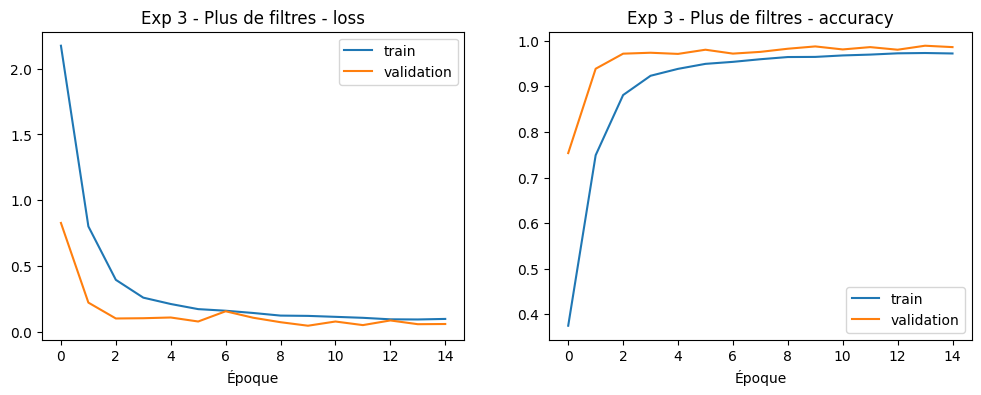

Exp 3 - Plus de filtres : accuracy validation = 0.9875


In [ ]:
lancer_experience("Exp 3 - Plus de filtres", "Exp 2 avec 64 / 128 filtres",
                  creer_cnn(nb_filtres=64, taux_dropout=0.5, augmentation=creer_augmentation()))

### Expérience 4 : learning rate

Même configuration que l'expérience 2, mais avec un learning rate 10 fois plus grand (0,01 au lieu de 0,001). On s'attend à un apprentissage instable, voire bloqué.

Epoch 1/30
490/490 - 9s - 19ms/step - accuracy: 0.1037 - loss: 3.3502 - val_accuracy: 0.2958 - val_loss: 2.5921
Epoch 2/30
490/490 - 12s - 25ms/step - accuracy: 0.2664 - loss: 2.5637 - val_accuracy: 0.3706 - val_loss: 1.9815
Epoch 3/30
490/490 - 7s - 15ms/step - accuracy: 0.3126 - loss: 2.2927 - val_accuracy: 0.3957 - val_loss: 1.8632
Epoch 4/30
490/490 - 5s - 11ms/step - accuracy: 0.3349 - loss: 2.1863 - val_accuracy: 0.3961 - val_loss: 1.8859
Epoch 5/30
490/490 - 6s - 12ms/step - accuracy: 0.3514 - loss: 2.1221 - val_accuracy: 0.4513 - val_loss: 1.7085
Epoch 6/30
490/490 - 5s - 11ms/step - accuracy: 0.3604 - loss: 2.0750 - val_accuracy: 0.4579 - val_loss: 1.6407
Epoch 7/30
490/490 - 6s - 12ms/step - accuracy: 0.3702 - loss: 2.0339 - val_accuracy: 0.4635 - val_loss: 1.6233
Epoch 8/30
490/490 - 5s - 11ms/step - accuracy: 0.3752 - loss: 2.0261 - val_accuracy: 0.4715 - val_loss: 1.5935
Epoch 9/30
490/490 - 6s - 12ms/step - accuracy: 0.3823 - loss: 1.9884 - val_accuracy: 0.4798 - val_loss

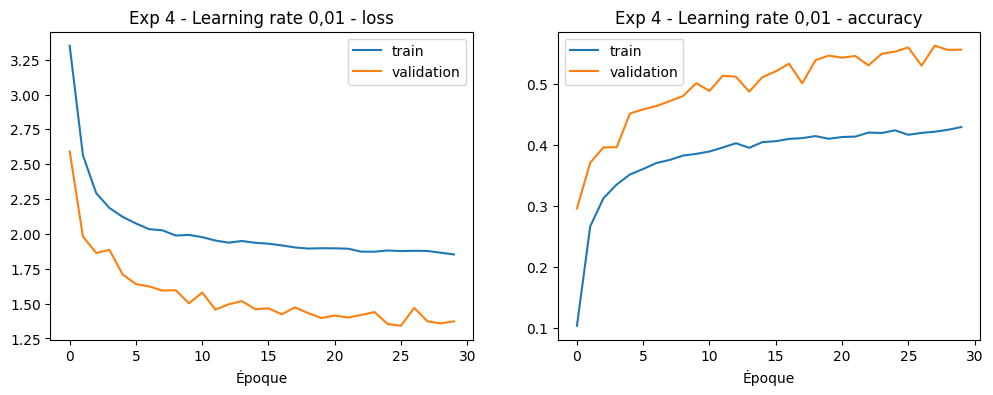

Exp 4 - Learning rate 0,01 : accuracy validation = 0.5594


In [ ]:
lancer_experience("Exp 4 - Learning rate 0,01", "Exp 2 avec learning rate 0,01",
                  creer_cnn(taux_dropout=0.5, augmentation=creer_augmentation()), learning_rate=0.01)

### Tableau comparatif

In [ ]:
tableau = pd.DataFrame(resultats)
tableau.round(4)

,expérience,modification,accuracy train,accuracy validation,écart train - val,loss validation,époques,paramètres,durée (s)
0,Réseau dense,Modèle de référence (partie 2),0.9544,0.8416,0.1128,0.8426,15,797739,33
1,CNN v1,CNN de base (partie 3),0.9993,0.9611,0.0382,0.1829,10,1125451,58
2,Exp 1 - Dropout,"CNN v1 + Dropout 0,5",0.9997,0.9808,0.0189,0.0898,21,1125451,91
3,Exp 2 - Augmentation,Exp 1 + Data Augmentation,0.9971,0.9838,0.0133,0.0595,14,1125451,92
4,Exp 3 - Plus de filtres,Exp 2 avec 64 / 128 filtres,0.9991,0.9875,0.0115,0.0453,15,2368619,124
5,"Exp 4 - Learning rate 0,01","Exp 2 avec learning rate 0,01",0.6328,0.5594,0.0734,1.3414,30,1125451,188


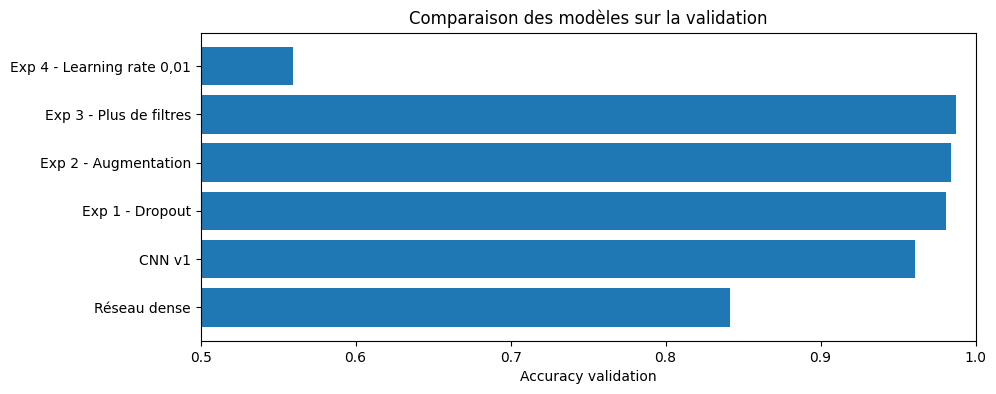

In [ ]:
plt.figure(figsize=(10, 4))
plt.barh(tableau["expérience"], tableau["accuracy validation"])
plt.xlim(0.5, 1.0)   # on coupe l'axe à 0.5 sinon les écarts entre les CNN sont invisibles
plt.xlabel("Accuracy validation")
plt.title("Comparaison des modèles sur la validation")
plt.show()

### Ce qu'on observe

| Expérience | Acc. validation | Écart train - val | Effet | Interprétation |
|---|---|---|---|---|
| CNN v1 (référence) | 96,1 % | 3,8 pts | Surapprend dès les premières époques | Le modèle mémorise le train |
| Exp 1 - Dropout | 98,1 % | 1,9 pt | +2 points, écart divisé par 2, loss val qui passe de 0,18 à 0,09 | Le réseau ne peut plus compter sur quelques neurones, il généralise mieux |
| Exp 2 - Augmentation | 98,4 % | 1,3 pt | +0,3 point, loss val 0,06 | Le modèle voit des images plus variées et devient plus robuste |
| Exp 3 - Plus de filtres | **98,75 %** | 1,2 pt | +0,4 point, mais 2,1 fois plus de paramètres (2,37 M) et 35 % de temps en plus | Plus de filtres = plus de motifs détectés. Le gain existe mais il est petit par rapport au coût |
| Exp 4 - lr 0,01 | 55,9 % | 7,3 pts | Le modèle n'apprend presque pas (63 % même sur le train) | Pas trop grand : les poids « sautent » au-dessus des minimums de la loss au lieu de s'en approcher |

Deux remarques :

- Sur l'expérience 2, l'accuracy de train affichée pendant `fit()` (autour de 95-96 %) est **plus basse** que celle de validation (98 %). Au début ça nous a paru bizarre, mais c'est logique : pendant l'entraînement, les images sont augmentées et le Dropout est actif, donc le train est plus difficile que la validation. Quand on recalcule l'accuracy de train avec `evaluate()` (sans Dropout ni augmentation), on retrouve 99,7 %.
- Pour l'expérience 4, on s'attendait à des courbes qui oscillent fortement. En fait la loss baisse, mais très lentement et en restant haute : le modèle reste bloqué vers 40 % d'accuracy de train. Il n'a même pas été arrêté par l'Early Stopping (30 époques). Ça confirme que 0,001 était un bon choix pour Adam ici.

**Bilan :** les trois premières expériences améliorent toutes le modèle, et c'est la régularisation (Dropout puis augmentation) qui apporte le plus. Ça confirme que le problème principal du CNN v1 était le surapprentissage, pas un manque de capacité.

### Choix du modèle final

On garde l'**expérience 3** (Dropout + Data Augmentation + 64/128 filtres) : meilleure accuracy de validation (98,75 %), meilleure loss de validation (0,045) et plus petit écart train - val (1,2 point). L'expérience 2 aurait été un choix défendable aussi, puisqu'elle est deux fois plus légère pour seulement 0,4 point de moins. Si le modèle devait tourner sur une petite carte embarquée dans une voiture, on prendrait probablement celle-là.

In [ ]:
# on prend le meilleur score de validation (et pas de test !)
meilleur_nom = tableau.loc[tableau["accuracy validation"].idxmax(), "expérience"]
modele_final = modeles[meilleur_nom]
print("Modèle final retenu :", meilleur_nom)

Modèle final retenu : Exp 3 - Plus de filtres


### Évaluation finale sur le test

Le test n'a servi à aucun choix jusqu'ici : c'est donc l'estimation la plus honnête de ce que le modèle ferait sur de nouvelles images. On ne l'utilise qu'ici, une seule fois.

In [ ]:
loss_test, acc_test = modele_final.evaluate(X_test, y_test, verbose=0)
print(f"Modèle final ({meilleur_nom}) - accuracy test : {acc_test:.4f} | loss test : {loss_test:.4f}")

probas_test = modele_final.predict(X_test, verbose=0)
pred_test = probas_test.argmax(axis=1)

Modèle final (Exp 3 - Plus de filtres) - accuracy test : 0.9791 | loss test : 0.0925


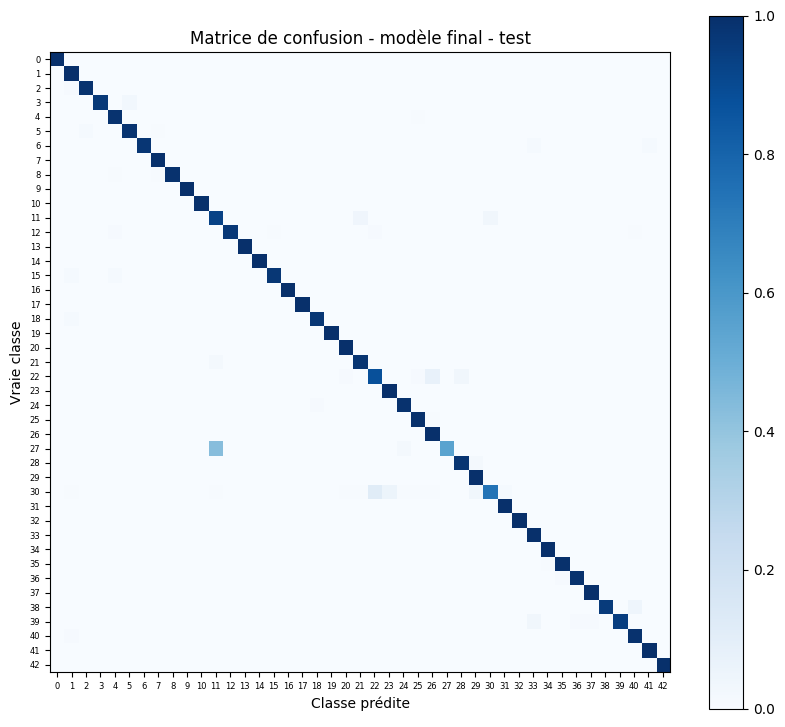

,vraie classe,classe prédite,nb erreurs
64,Contournement par la droite,Sens giratoire,30
46,Passage piétons,Priorité à la prochaine intersection,26
21,Priorité à la prochaine intersection,Double virage,17
53,Neige ou verglas,Chaussée déformée,17
3,Limitation 60 km/h,Limitation 80 km/h,14
22,Priorité à la prochaine intersection,Neige ou verglas,14
42,Chaussée déformée,Feux tricolores,9
10,Limitation 80 km/h,Limitation 50 km/h,8
54,Neige ou verglas,Chaussée glissante,8
25,Route prioritaire,Chaussée déformée,7


In [ ]:
matrice_test = afficher_matrice_confusion(y_test, pred_test, "Matrice de confusion - modèle final - test")
tableau_confusions(matrice_test)

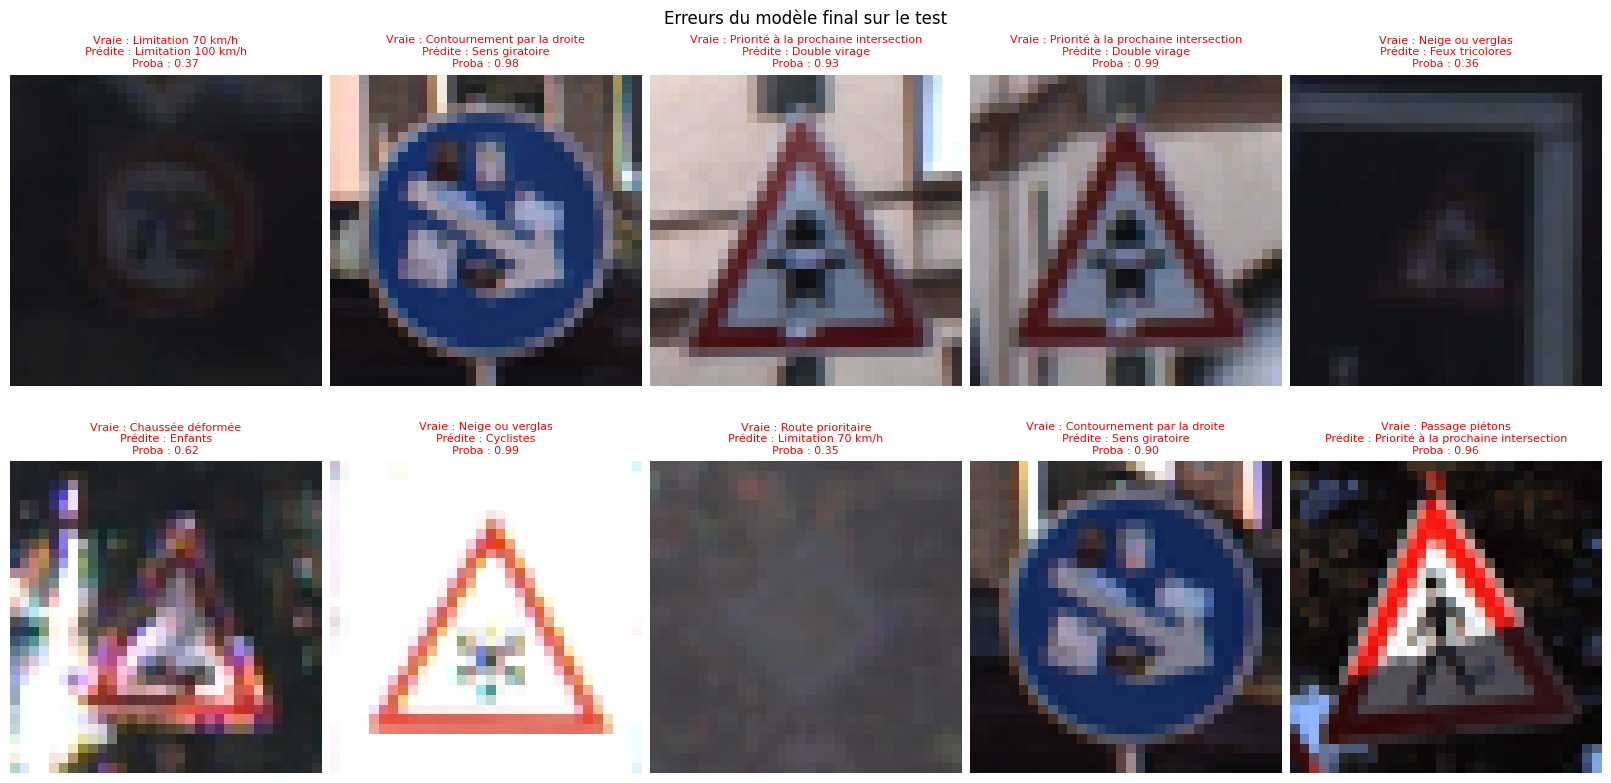

In [ ]:
erreurs_test = np.where(pred_test != y_test)[0]
afficher_exemples(X_test, y_test, probas_test, rng.choice(erreurs_test, size=min(10, len(erreurs_test)), replace=False),
                  "Erreurs du modèle final sur le test")

In [ ]:
# sauvegarde au format Keras (le fichier apparaît dans l'onglet Fichiers de Colab)
modele_final.save("modele_final.keras")
print("Modèle sauvegardé dans modele_final.keras")

Modèle sauvegardé dans modele_final.keras


### Résultat sur le test

On obtient **97,9 %** sur le test contre 98,75 % en validation. Une petite baisse était attendue, puisqu'on a choisi le modèle en regardant la validation : son score y est forcément un peu optimiste. Moins d'un point d'écart, c'est rassurant, ça veut dire que le modèle généralise bien et que notre validation séparée par série était fiable.

Les principales confusions sur le test :
- « Contournement par la droite » prédit « Sens giratoire » (30 erreurs) : deux panneaux ronds bleus avec des flèches blanches ;
- « Passage piétons » prédit « Priorité à la prochaine intersection » (26) : deux triangles rouges, seul le pictogramme change ;
- « Priorité à la prochaine intersection » prédit « Double virage » (17) et « Neige ou verglas » prédit « Chaussée déformée » (17) : même problème ;
- « Limitation 60 km/h » prédit « Limitation 80 km/h » (14) : en basse résolution, le 6 et le 8 se ressemblent beaucoup.

On retrouve les mêmes difficultés qu'en validation : des panneaux de même forme et de même couleur qui ne diffèrent que par un détail de quelques pixels.

## Démonstration

`predire_top3` applique **le même prétraitement** qu'à l'entraînement (RGB, 32 x 32, division par 255) et renvoie les 3 classes les plus probables. C'est important : si on oubliait par exemple de diviser par 255, le modèle recevrait des valeurs 255 fois trop grandes et ses prédictions n'auraient plus de sens.

In [ ]:
def predire_top3(image, modele):
    """Prend une image PIL de n'importe quelle taille, renvoie [(nom de classe, probabilité)] x 3."""
    x = np.array(image.convert("RGB").resize((TAILLE_IMAGE, TAILLE_IMAGE))).astype("float32") / 255.0
    x = np.expand_dims(x, axis=0)            # le modèle attend un batch : (1, 32, 32, 3)
    probas = modele.predict(x, verbose=0)[0]
    top3 = probas.argsort()[::-1][:3]        # indices des 3 plus grandes probabilités
    return [(NOMS_CLASSES[i], probas[i]) for i in top3]

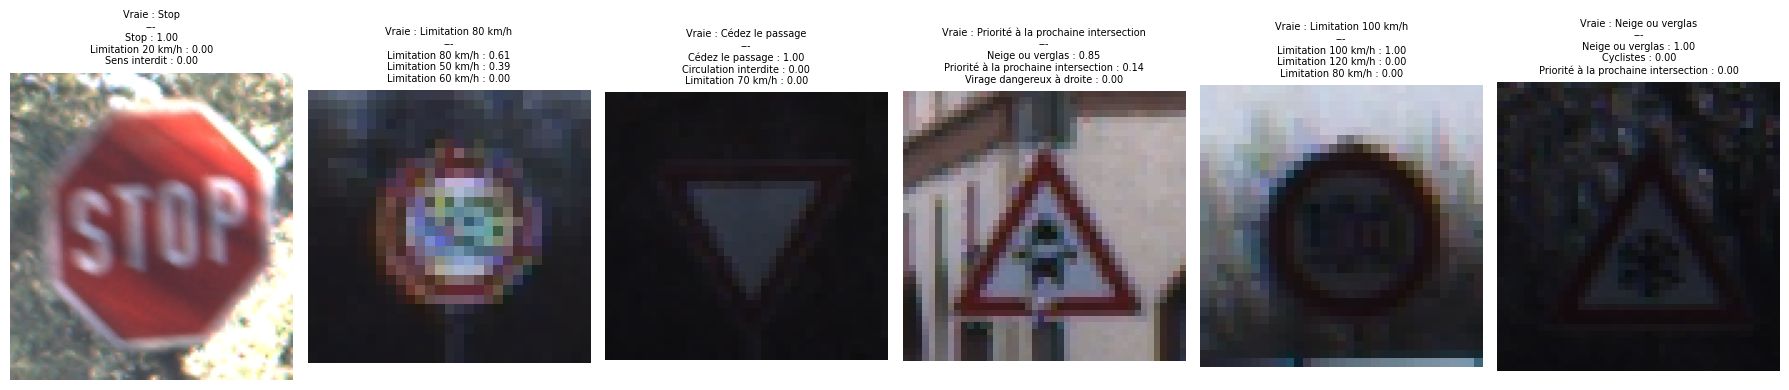

In [ ]:
# 6 images de test relues directement depuis les fichiers, pour tester toute la chaîne
choix = test_df.sample(6, random_state=7)

fig, axes = plt.subplots(1, 6, figsize=(18, 4.5))
for ax, (_, ligne) in zip(axes, choix.iterrows()):
    image = Image.open(os.path.join(DOSSIER, ligne["Path"]))
    top3 = predire_top3(image, modele_final)
    ax.imshow(image)
    texte = "\n".join(f"{nom} : {p:.2f}" for nom, p in top3)
    ax.set_title(f"Vraie : {NOMS_CLASSES[ligne['ClassId']]}\n---\n{texte}", fontsize=7)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Tester ses propres photos :** passer `TESTER_MES_PHOTOS` à `True` et exécuter la cellule (dans Colab). La photo doit montrer un panneau **recadré et centré**, comme dans le dataset. Le modèle ne sait pas trouver un panneau dans une scène complète : pour ça il faudrait un détecteur (type YOLO) en amont.

In [ ]:
TESTER_MES_PHOTOS = False

if TESTER_MES_PHOTOS:
    from google.colab import files   # ne marche que dans Colab
    envoyes = files.upload()
    for nom_fichier in envoyes:
        image = Image.open(nom_fichier)
        plt.imshow(image)
        plt.axis("off")
        plt.show()
        for nom, p in predire_top3(image, modele_final):
            print(f"{nom} : {p:.2f}")

## 7. Bonus : Transfer Learning

**Principe :** plutôt que de partir de zéro, on reprend un réseau déjà entraîné sur ImageNet (1,4 million de photos, 1 000 catégories). Ses couches savent déjà détecter des bords, des textures, des formes. On enlève sa couche de sortie et on en met une nouvelle à 43 neurones.

On a pris **MobileNetV2** parce qu'il est léger et rapide, ce qui compte sur Colab.

En deux temps :
1. **Réseau gelé** : on n'entraîne que la nouvelle couche de sortie, les poids ImageNet ne bougent pas.
2. **Fine-tuning** : on dégèle tout et on réentraîne avec un learning rate très petit, pour adapter les filtres aux panneaux sans casser ce qui a été appris sur ImageNet.

Deux détails techniques :
- MobileNetV2 a été entraîné sur des images bien plus grandes (224 x 224). 96 x 96 est la plus petite taille pour laquelle Keras fournit des poids, donc on agrandit nos images de 32 à 96 directement dans le modèle avec une couche `Resizing`.
- Il attend des pixels entre -1 et 1, alors que les nôtres sont entre 0 et 1 : on applique x * 2 - 1 avec une couche `Rescaling`.

On met la construction dans une fonction pour pouvoir recréer un modèle neuf plus bas (voir 7.3).

In [ ]:
def creer_modele_tl():
    """MobileNetV2 pré-entraîné sur ImageNet (gelé) + nouvelle tête à 43 classes. Renvoie (modèle, base)."""
    # include_top=False : on enlève la couche de sortie à 1000 classes d'ImageNet
    base = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights="imagenet")
    base.trainable = False

    entree = keras.Input(shape=(TAILLE_IMAGE, TAILLE_IMAGE, 3))
    x = layers.Resizing(96, 96)(entree)
    x = layers.Rescaling(2.0, offset=-1.0)(x)     # [0, 1] -> [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)         # une valeur par feature map -> vecteur de 1280
    x = layers.Dropout(0.3)(x)
    sortie = layers.Dense(NB_CLASSES, activation="softmax")(x)
    return keras.Model(entree, sortie, name="transfer_learning"), base


modele_tl, base = creer_modele_tl()
modele_tl.summary()   # on voit bien les ~2,26 M paramètres gelés contre 55 000 entraînables

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 43)             │        55,083 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,313,067 (8.82 MB)

 Trainable params: 55,083 (215.17 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
490/490 - 32s - 65ms/step - accuracy: 0.6528 - loss: 1.1654 - val_accuracy: 0.6726 - val_loss: 1.0618
Epoch 2/10
490/490 - 8s - 15ms/step - accuracy: 0.8425 - loss: 0.5023 - val_accuracy: 0.7029 - val_loss: 0.9730
Epoch 3/10
490/490 - 7s - 15ms/step - accuracy: 0.8768 - loss: 0.3889 - val_accuracy: 0.7122 - val_loss: 0.9480
Epoch 4/10
490/490 - 7s - 15ms/step - accuracy: 0.8963 - loss: 0.3259 - val_accuracy: 0.7178 - val_loss: 0.9579
Epoch 5/10
490/490 - 7s - 15ms/step - accuracy: 0.9034 - loss: 0.2955 - val_accuracy: 0.7215 - val_loss: 0.9584
Epoch 6/10
490/490 - 7s - 15ms/step - accuracy: 0.9123 - loss: 0.2685 - val_accuracy: 0.7289 - val_loss: 0.9759
Epoch 7/10
490/490 - 7s - 15ms/step - accuracy: 0.9160 - loss: 0.2564 - val_accuracy: 0.7196 - val_loss: 1.0019
Epoch 8/10
490/490 - 8s - 17ms/step - accuracy: 0.9203 - loss: 0.2419 - val_accuracy: 0.7210 - val_loss: 1.0303


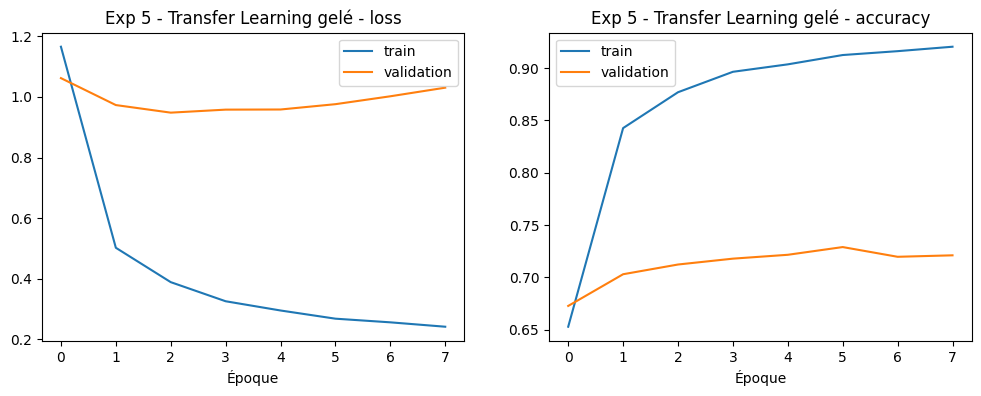

Exp 5 - Transfer Learning gelé : accuracy validation = 0.7122


In [ ]:
# étape 1 : seule la nouvelle sortie est entraînée
lancer_experience("Exp 5 - Transfer Learning gelé", "MobileNetV2 ImageNet gelé + nouvelle sortie",
                  modele_tl, learning_rate=0.001, epoques=EPOQUES_TL)

Epoch 1/10
490/490 - 121s - 248ms/step - accuracy: 0.5851 - loss: 1.6984 - val_accuracy: 0.6144 - val_loss: 1.3772
Epoch 2/10
490/490 - 22s - 46ms/step - accuracy: 0.7986 - loss: 0.6508 - val_accuracy: 0.6341 - val_loss: 1.3063
Epoch 3/10
490/490 - 22s - 46ms/step - accuracy: 0.8831 - loss: 0.3585 - val_accuracy: 0.6618 - val_loss: 1.2642
Epoch 4/10
490/490 - 22s - 45ms/step - accuracy: 0.9258 - loss: 0.2257 - val_accuracy: 0.7078 - val_loss: 1.0735
Epoch 5/10
490/490 - 22s - 45ms/step - accuracy: 0.9534 - loss: 0.1479 - val_accuracy: 0.7632 - val_loss: 0.8390
Epoch 6/10
490/490 - 22s - 45ms/step - accuracy: 0.9689 - loss: 0.1006 - val_accuracy: 0.8140 - val_loss: 0.6507
Epoch 7/10
490/490 - 22s - 45ms/step - accuracy: 0.9812 - loss: 0.0696 - val_accuracy: 0.8440 - val_loss: 0.5610
Epoch 8/10
490/490 - 22s - 45ms/step - accuracy: 0.9878 - loss: 0.0488 - val_accuracy: 0.8548 - val_loss: 0.5316
Epoch 9/10
490/490 - 22s - 45ms/step - accuracy: 0.9923 - loss: 0.0344 - val_accuracy: 0.8631 

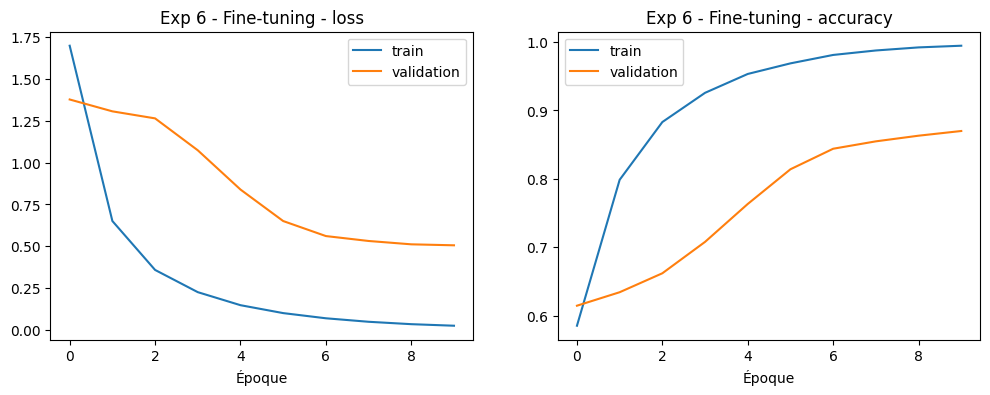

Exp 6 - Fine-tuning : accuracy validation = 0.8700


In [ ]:
# étape 2 : on dégèle tout et on réentraîne avec un lr 100 fois plus petit
# (lancer_experience recompile le modèle, ce qui est nécessaire pour que le changement de trainable soit pris en compte)
base.trainable = True
lancer_experience("Exp 6 - Fine-tuning", "Exp 5 puis MobileNetV2 dégelé, learning rate 0,00001",
                  modele_tl, learning_rate=0.00001, epoques=EPOQUES_TL)

In [ ]:
pd.DataFrame(resultats).round(4)

,expérience,modification,accuracy train,accuracy validation,écart train - val,loss validation,époques,paramètres,durée (s)
0,Réseau dense,Modèle de référence (partie 2),0.9544,0.8416,0.1128,0.8426,15,797739,33
1,CNN v1,CNN de base (partie 3),0.9993,0.9611,0.0382,0.1829,10,1125451,58
2,Exp 1 - Dropout,"CNN v1 + Dropout 0,5",0.9997,0.9808,0.0189,0.0898,21,1125451,91
3,Exp 2 - Augmentation,Exp 1 + Data Augmentation,0.9971,0.9838,0.0133,0.0595,14,1125451,92
4,Exp 3 - Plus de filtres,Exp 2 avec 64 / 128 filtres,0.9991,0.9875,0.0115,0.0453,15,2368619,124
5,"Exp 4 - Learning rate 0,01","Exp 2 avec learning rate 0,01",0.6328,0.5594,0.0734,1.3414,30,1125451,188
6,Exp 5 - Transfer Learning gelé,MobileNetV2 ImageNet gelé + nouvelle sortie,0.9369,0.7122,0.2247,0.9480,8,2313067,85
7,Exp 6 - Fine-tuning,"Exp 5 puis MobileNetV2 dégelé, learning rate 0...",0.9965,0.8700,0.1265,0.5058,10,2313067,322


### 7.1 Interprétation

| Modèle | Acc. validation | Paramètres | Durée |
|---|---|---|---|
| Notre CNN (exp 3) | 98,75 % | 2,37 M | 124 s |
| MobileNetV2 gelé | 71,2 % | 2,31 M (55 000 entraînés) | 85 s |
| MobileNetV2 fine-tuné | 87,0 % | 2,31 M | 322 s |

**Le Transfer Learning fait nettement moins bien que notre CNN**, pour un modèle de taille comparable et plus lent (45 ms par pas contre 16 ms pour l'exp 3, soit à peu près 3 fois plus lent).

Plusieurs raisons à notre avis :
- MobileNetV2 a appris sur ImageNet, donc de grandes photos d'objets du quotidien. Nos panneaux font 32 x 32 et sont agrandis en 96 x 96, donc très flous. Les filtres ImageNet ne sont pas faits pour ce genre d'images.
- **Réseau gelé :** 93,7 % sur le train mais seulement 71,2 % en validation. Les caractéristiques ImageNet permettent de séparer les images déjà vues, mais elles se généralisent mal à de nouveaux panneaux. Une explication possible est qu'avec environ 30 photos presque identiques par série, il n'y a en réalité qu'un peu plus de 1 000 panneaux différents dans le train, ce qui est peu pour une tête linéaire sur 1 280 caractéristiques.
- **Fine-tuning :** dégeler le réseau fait gagner 16 points (de 71 % à 87 %). La loss de validation baissait encore à la dernière époque, donc avec plus d'époques le score aurait sans doute continué à monter.

### 7.2 Un problème repéré dans le fine-tuning

En relisant les logs, quelque chose ne collait pas : à la première époque du fine-tuning, l'accuracy de train **chute** de près de 90 % à 58 % (et la validation de 71 % à 61 %), alors qu'avec un learning rate de 0,00001 les poids devraient à peine bouger.

On a cherché et la cause vient des couches **BatchNormalization** de MobileNetV2. On a pourtant écrit `base(x, training=False)` pour les garder en mode inférence, mais avec la version de Keras utilisée (Keras 3, TensorFlow 2.21), cet argument n'est pas respecté une fois que `base.trainable = True`. On l'a vérifié avec un petit test séparé : après un seul `fit()`, les `moving_mean` des BatchNorm ont changé. Concrètement :
- pendant l'entraînement, les BatchNorm normalisent avec les statistiques du batch (nos panneaux) au lieu de celles d'ImageNet, donc la tête de classification apprise en étape 1 reçoit d'un coup des valeurs différentes : d'où la chute ;
- en même temps, les moyennes mobiles d'ImageNet sont progressivement écrasées.

Ça n'empêche pas le réseau de réapprendre (on finit à 87 %), mais on perd une bonne partie de l'intérêt du pré-entraînement. La correction habituelle est de **laisser les couches BatchNormalization gelées** pendant le fine-tuning (dans Keras 3, une BatchNorm avec `trainable=False` tourne toujours en mode inférence).

### 7.3 Fine-tuning corrigé

La cellule ci-dessous refait les deux étapes sur un MobileNetV2 neuf (le précédent a ses statistiques BatchNorm modifiées), cette fois avec les BatchNorm gelées. Elle est désactivée par défaut car elle prend environ 7 à 8 minutes sur GPU : passer `RELANCER_FINE_TUNING_CORRIGE` à `True` pour la lancer.

In [ ]:
RELANCER_FINE_TUNING_CORRIGE = False

if RELANCER_FINE_TUNING_CORRIGE:
    modele_tl2, base2 = creer_modele_tl()
    # étape 1 identique à l'exp 5
    lancer_experience("Exp 7a - TL gelé (bis)", "Comme exp 5, sur un modèle neuf",
                      modele_tl2, learning_rate=0.001, epoques=EPOQUES_TL)

    # étape 2 : on dégèle tout SAUF les BatchNorm
    base2.trainable = True
    for couche in base2.layers:
        if isinstance(couche, layers.BatchNormalization):
            couche.trainable = False
    lancer_experience("Exp 7 - Fine-tuning, BN gelées", "Exp 6 avec les BatchNormalization gelées",
                      modele_tl2, learning_rate=0.00001, epoques=EPOQUES_TL)

    display(pd.DataFrame(resultats).round(4))

## Conclusion

- **Données :** GTSRB, 43 classes, 39 209 images de train et 12 630 de test, avec un fort déséquilibre (de 210 à 2 250 images par classe). On a séparé train et validation par série pour éviter que des photos quasi identiques se retrouvent des deux côtés.
- **Réseau dense :** 84,2 % en validation. Il surapprend et ne tient pas compte de la structure spatiale de l'image.
- **CNN :** 96,1 % pour la première version, soit 12 points de plus, avec des filtres partagés sur toute l'image.
- **Expériences :** le Dropout (+2 points) et la Data Augmentation réduisent nettement le surapprentissage. Doubler les filtres apporte encore un peu. Un learning rate de 0,01 empêche quasiment l'apprentissage.
- **Modèle final :** CNN 64/128 filtres + Dropout + Data Augmentation, **98,75 % en validation et 97,9 % sur le test**.
- **Erreurs restantes :** surtout des confusions entre panneaux de même forme et de même couleur (triangles de danger, ronds bleus, limitations de vitesse) qui ne diffèrent que par un petit pictogramme. Elles touchent plutôt les classes rares, et les images mal classées sont en moyenne plus claires.
- **Transfer Learning :** MobileNetV2 fait moins bien (87 % après fine-tuning), en partie parce que ses filtres ImageNet sont peu adaptés à des images de 32 x 32, mais aussi à cause du problème de BatchNormalization repéré en 7.2. On ne peut donc pas conclure trop vite que le Transfer Learning est moins bon sur ce dataset ; la version corrigée (7.3) permettrait de trancher.

**Ce qu'on ferait avec plus de temps :**
- choisir un fold de validation qui contient les 43 classes ;
- recadrer les images avec les coordonnées `Roi` fournies dans les CSV, pour que le panneau occupe toute l'image ;
- compenser le déséquilibre avec `class_weight` ;
- passer en 48 x 48 pour mieux voir les pictogrammes ;
- ajouter de la BatchNormalization dans notre CNN ;
- mettre un détecteur (YOLO par exemple) en amont pour trouver les panneaux dans une scène complète avant de les classer.